# Exploratory Data Analysis

## Dataset Overview

The shape and structure of both datasets: the flights file and the hourly weather file.

### O1. Setup and load

VS Code runs the notebook from `notebooks/`, so data paths start with `../data/raw/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

RAW = Path("../data/raw")
flights = pd.read_csv(RAW / "Flight_Data_With_Weather_Final.csv", low_memory=False, parse_dates=["FL_DATE"])
weather = pd.read_csv(RAW / "challenge5_hourly_weather_ATL_DFW.csv", parse_dates=["time_utc", "time_local"])

### O2. Shape

In [2]:
def shape_summary(name: str, data: pd.DataFrame, date_col: str) -> dict:
    return {
        "dataset": name,
        "rows": len(data),
        "columns": data.shape[1],
        "memory_mb": round(data.memory_usage(deep=True).sum() / 1e6, 1),
        "first": data[date_col].min(),
        "last": data[date_col].max(),
    }

pd.DataFrame([
    shape_summary("flights", flights, "FL_DATE"),
    shape_summary("hourly weather", weather, "time_utc"),
]).set_index("dataset")

,rows,columns,memory_mb,first,last
dataset,,,,,
flights,148273,123,254.7,2023-01-01,2025-07-31 00:00:00
hourly weather,45264,16,7.8,2023-01-01,2025-07-31 23:00:00


### O3. Column summary: flights file

One row per column: its group, type, how much is missing, how many distinct values, and an example value.

In [3]:
WEATHER_PREFIXES = {"temp", "prcp", "wspd", "wpgt", "pres", "snow", "coco"}
DELAY_CAUSES = {"CARRIER_DELAY", "WEATHER_DELAY", "NAS_DELAY", "SECURITY_DELAY", "LATE_AIRCRAFT_DELAY"}

def flight_column_group(col: str) -> str:
    if col.split("_")[0] in WEATHER_PREFIXES:
        return "weather (origin)" if col.endswith("_ORIGIN") else "weather (dest)"
    if col.startswith("DIV"):
        return "diversion details"
    if col in DELAY_CAUSES:
        return "delay causes"
    if col in {"YEAR", "QUARTER", "MONTH", "DAY_OF_MONTH", "DAY_OF_WEEK", "FL_DATE"}:
        return "date"
    if col.startswith("OP_") or col == "TAIL_NUM":
        return "carrier"
    if col.startswith("ORIGIN"):
        return "origin"
    if col.startswith("DEST"):
        return "destination"
    if col in {"CRS_DEP_TIME", "TAXI_OUT", "WHEELS_OFF"} or col.startswith("DEP_"):
        return "departure"
    if col in {"CRS_ARR_TIME", "TAXI_IN", "WHEELS_ON"} or col.startswith("ARR_"):
        return "arrival"
    if col in {"CANCELLED", "CANCELLATION_CODE", "DIVERTED"}:
        return "cancellation / diversion"
    if col in {"FIRST_DEP_TIME", "TOTAL_ADD_GTIME", "LONGEST_ADD_GTIME"}:
        return "gate return"
    return "flight summary"

def column_summary(data: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "dtype": data.dtypes.astype(str),
        "non_null": data.notna().sum(),
        "pct_missing": (data.isna().mean() * 100).round(1),
        "n_unique": data.nunique(),
        "example": [data[c].dropna().iloc[0] if data[c].notna().any() else None for c in data.columns],
    })

flight_columns = column_summary(flights)
flight_columns.insert(0, "group", [flight_column_group(c) for c in flights.columns])
flight_columns

,group,dtype,non_null,pct_missing,n_unique,example
YEAR,date,int64,148273,0.0,3,2023
QUARTER,date,int64,148273,0.0,4,1
MONTH,date,int64,148273,0.0,12,1
DAY_OF_MONTH,date,int64,148273,0.0,31,16
DAY_OF_WEEK,date,int64,148273,0.0,7,1
FL_DATE,date,datetime64[us],148273,0.0,943,2023-01-16 00:00:00
OP_UNIQUE_CARRIER,carrier,str,148273,0.0,15,9E
OP_CARRIER_AIRLINE_ID,carrier,int64,148273,0.0,15,20363
OP_CARRIER,carrier,str,148273,0.0,15,9E
TAIL_NUM,carrier,str,147952,0.2,6308,N306PQ


### O4. Column groups: flights file

How many columns each group has, and how many of them are mostly empty (over 90% missing).

In [4]:
flight_columns.groupby("group").agg(
    n_columns=("dtype", "size"),
    mostly_empty=("pct_missing", lambda s: (s > 90).sum()),
    avg_pct_missing=("pct_missing", "mean"),
).round(1).sort_values("n_columns", ascending=False)

,n_columns,mostly_empty,avg_pct_missing
group,,,
diversion details,46,44,95.6
origin,9,0,0.0
destination,9,0,0.0
departure,9,0,1.0
arrival,9,0,1.1
weather (origin),7,0,0.0
weather (dest),7,0,0.0
flight summary,6,0,0.5
date,6,0,0.0


### O5. Column summary: hourly weather file

In [5]:
column_summary(weather)

,dtype,non_null,pct_missing,n_unique,example
airport,str,45264,0.0,2,ATL
runway_heading_deg,int64,45264,0.0,2,80
time_utc,datetime64[us],45264,0.0,22632,2023-01-01 00:00:00
time_local,datetime64[us],45264,0.0,22631,2022-12-31 19:00:00
temp_c,float64,45264,0.0,139,14.4
dewpoint_c,float64,45264,0.0,427,13.3
rel_humidity_pct,int64,45264,0.0,91,93
precip_mm,float64,45211,0.1,146,0.0
wind_dir_deg,int64,45264,0.0,231,0
wind_speed_kmh,float64,45264,0.0,66,0.0


### O6. Sample rows

First five rows of each file. The flights file is transposed so all 123 columns are readable.

In [6]:
flights.head().T

,0,1,2,3,4
YEAR,2023,2023,2023,2023,2023
QUARTER,1,1,1,1,1
MONTH,1,1,1,1,1
DAY_OF_MONTH,16,30,30,16,2
DAY_OF_WEEK,1,1,1,1,1
FL_DATE,2023-01-16 00:00:00,2023-01-30 00:00:00,2023-01-30 00:00:00,2023-01-16 00:00:00,2023-01-02 00:00:00
OP_UNIQUE_CARRIER,9E,9E,9E,9E,9E
OP_CARRIER_AIRLINE_ID,20363,20363,20363,20363,20363
OP_CARRIER,9E,9E,9E,9E,9E
TAIL_NUM,N306PQ,N923XJ,N8918B,N296PQ,N368CA


In [7]:
weather.head()

,airport,runway_heading_deg,time_utc,time_local,temp_c,dewpoint_c,rel_humidity_pct,precip_mm,wind_dir_deg,wind_speed_kmh,wind_gust_kmh,pressure_hpa,condition_code,headwind_kmh,crosswind_kmh,tailwind_kmh
0,ATL,80,2023-01-01 00:00:00,2022-12-31 19:00:00,14.4,13.3,93,0.0,0,0.0,NaN,1016.7,3.0,0.0,0.0,0.0
1,ATL,80,2023-01-01 01:00:00,2022-12-31 20:00:00,14.4,13.3,93,0.0,0,0.0,NaN,1016.7,3.0,0.0,0.0,0.0
2,ATL,80,2023-01-01 02:00:00,2022-12-31 21:00:00,13.3,12.8,97,0.0,230,7.6,NaN,1017.3,2.0,-6.6,3.8,6.6
3,ATL,80,2023-01-01 03:00:00,2022-12-31 22:00:00,13.3,12.8,97,0.0,250,5.4,NaN,1017.4,5.0,-5.3,0.9,5.3
4,ATL,80,2023-01-01 04:00:00,2022-12-31 23:00:00,13.3,12.8,97,0.0,250,5.4,NaN,1017.4,5.0,-5.3,0.9,5.3


### O7. Numeric summary

In [8]:
flights.describe().T

,count,mean,min,25%,50%,75%,max,std
YEAR,148273.0,2023.852832,2023.0,2023.0,2024.0,2024.0,2025.0,0.765111
QUARTER,148273.0,2.354232,1.0,1.0,2.0,3.0,4.0,1.079542
MONTH,148273.0,6.031921,1.0,3.0,6.0,9.0,12.0,3.301618
DAY_OF_MONTH,148273.0,15.459915,1.0,8.0,15.0,24.0,31.0,9.010895
DAY_OF_WEEK,148273.0,3.982202,1.0,2.0,4.0,6.0,7.0,2.005614
FL_DATE,148273,2024-04-23 11:52:14.124216,2023-01-01 00:00:00,2023-09-01 00:00:00,2024-04-29 00:00:00,2024-12-12 00:00:00,2025-07-31 00:00:00,NaN
OP_CARRIER_AIRLINE_ID,148273.0,19901.659142,19393.0,19790.0,19805.0,20304.0,20452.0,368.81817
OP_CARRIER_FL_NUM,148273.0,2314.830778,1.0,1087.0,2070.0,3325.0,8816.0,1554.436067
ORIGIN_AIRPORT_ID,148273.0,12641.213329,10140.0,11292.0,12889.0,13930.0,15919.0,1512.083023
ORIGIN_AIRPORT_SEQ_ID,148273.0,1264125.374768,1014005.0,1129202.0,1288904.0,1393008.0,1591905.0,151208.122097


In [9]:
weather.describe().T

,count,mean,min,25%,50%,75%,max,std
runway_heading_deg,45264.0,130.0,80.0,80.0,130.0,180.0,180.0,50.000552
time_utc,45264,2024-04-16 11:30:00,2023-01-01 00:00:00,2023-08-24 17:45:00,2024-04-16 11:30:00,2024-12-08 05:15:00,2025-07-31 23:00:00,NaN
time_local,45264,2024-04-16 06:39:29.220572,2022-12-31 18:00:00,2023-08-24 13:00:00,2024-04-16 07:00:00,2024-12-08 00:00:00,2025-07-31 19:00:00,NaN
temp_c,45264.0,19.507266,-11.7,13.3,20.6,26.1,42.8,9.131315
dewpoint_c,45264.0,11.344181,-20.7,4.1,13.9,19.0,26.7,9.156814
rel_humidity_pct,45264.0,62.568421,8.0,48.0,63.0,79.0,100.0,19.484865
precip_mm,45211.0,0.134085,0.0,0.0,0.0,0.0,62.5,1.036841
wind_dir_deg,45264.0,181.468231,0.0,100.0,180.0,270.0,360.0,102.574215
wind_speed_kmh,45264.0,14.695095,0.0,9.4,13.0,18.4,86.4,8.032424
wind_gust_kmh,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### O8. Categorical summary

Text columns: number of distinct values and the five most common.

In [10]:
def categorical_summary(data: pd.DataFrame) -> pd.DataFrame:
    text_cols = data.select_dtypes(include=["object", "string"]).columns
    return pd.DataFrame({
        "n_unique": [data[c].nunique() for c in text_cols],
        "top_5": [data[c].value_counts().head(5).to_dict() for c in text_cols],
    }, index=text_cols)

categorical_summary(flights)

,n_unique,top_5
OP_UNIQUE_CARRIER,15,"{'WN': 35006, 'DL': 22643, 'AA': 22457, 'UA': ..."
OP_CARRIER,15,"{'WN': 35006, 'DL': 22643, 'AA': 22457, 'UA': ..."
TAIL_NUM,6308,"{'N486HA': 117, 'N478HA': 108, 'N489HA': 107, ..."
ORIGIN,136,"{'ATL': 8415, 'DFW': 7736, 'DEN': 7687, 'ORD':..."
ORIGIN_CITY_NAME,131,"{'Chicago, IL': 9064, 'Atlanta, GA': 8415, 'Da..."
ORIGIN_STATE_ABR,43,"{'TX': 17161, 'CA': 16511, 'FL': 14290, 'IL': ..."
ORIGIN_STATE_NM,43,"{'Texas': 17161, 'California': 16511, 'Florida..."
DEST,350,"{'ATL': 5429, 'DEN': 5408, 'ORD': 4634, 'LAX':..."
DEST_CITY_NAME,344,"{'Chicago, IL': 6639, 'Atlanta, GA': 5429, 'De..."
DEST_STATE_ABR,52,"{'CA': 17540, 'TX': 14506, 'FL': 13894, 'NY': ..."


In [11]:
categorical_summary(weather)

,n_unique,top_5
airport,2,"{'ATL': 22632, 'DFW': 22632}"


### O9. Data guide

The organizers' guide (`challenge5_data_guide.xlsx`): column meanings for the hourly weather file, and the challenge rules.

In [12]:
guide = pd.read_excel(RAW / "challenge5_data_guide.xlsx", sheet_name=None)
for sheet, table in guide.items():
    print(f"sheet: {sheet}")
    with pd.option_context("display.max_colwidth", None):
        display(table)

sheet: weather_columns


,column,meaning
0,airport,ATL or DFW
1,runway_heading_deg,"Assumed heading: ATL 80, DFW 180"
2,time_utc / time_local,Observation hour (UTC and airport local time)
3,wind_dir_deg,"Direction the wind blows FROM, degrees true. 0 with 0 speed = calm"
4,headwind_kmh,wind_speed x cos(wind_dir - runway_heading); negative = tailwind
5,crosswind_kmh,|wind_speed x sin(wind_dir - runway_heading)|
6,tailwind_kmh,Tailwind component (0 if headwind)
7,condition_code,"Meteostat code: 1-2 clear, 3-4 cloudy, 5-6 fog, 7-9 rain, 14-16 snow, 25-27 thunderstorm"
8,source,"Meteostat hourly (NOAA ISD), stations 72219 (ATL) and 72259 (DFW)"


sheet: rules


,topic,detail
0,Main target,"Classify each ATL/DFW flight: will it be delayed more than 45 minutes? (ARR_DELAY > 45 for arrivals, DEP_DELAY > 45 for departures)"
1,Arrival rate (AAR),"Optional. Flight_Data_With_Weather_Final.csv is a sample (~6 ATL arrivals a day), so hourly AAR cannot be measured from it. Teams who want AAR may pull the full BTS on-time data automatically."
2,No leakage,"Only use weather observed at least 3 hours before the scheduled time you predict for (join on airport + hour, then shift by 3-12 hours)."
3,Columns to ignore,wpgt_* (98% zero) and snow_* (always zero) in Flight_Data_With_Weather_Final.csv are placeholders.
4,Times,Flight times are local (hhmm). Weather file has both UTC and local hours.
5,Generality,Build a pipeline that accepts any airport code; demo and score on ATL and DFW.
6,Normalise,"Compare delay rates (share of flights), not raw delay minutes, across airports."


## A. Coverage and Scope

How much of the flights file is ATL/DFW, how dense it is per day and per hour, and which airports could test the "any airport code" requirement.
Both directions count: a departure from ATL/DFW and an arrival into ATL/DFW are each a prediction target.

In [13]:
HUBS = ["ATL", "DFW"]
HUB_TZ = {"ATL": "America/New_York", "DFW": "America/Chicago"}

def hour_of(hhmm: pd.Series) -> pd.Series:
    """HHMM number -> hour 0-23 (2400 becomes 0). Drop NaNs before calling."""
    return (hhmm // 100).astype(int) % 24

all_dates = pd.date_range(flights["FL_DATE"].min(), flights["FL_DATE"].max(), freq="D")

### A1. All airports

Flights by origin and destination, and how many airports have enough rows to test the pipeline beyond ATL/DFW.

In [14]:
airports = pd.DataFrame({
    "as_origin": flights["ORIGIN"].value_counts(),
    "as_dest": flights["DEST"].value_counts(),
}).fillna(0).astype(int)
airports["total"] = airports["as_origin"] + airports["as_dest"]
airports = airports.sort_values("total", ascending=False)

print(f"{len(airports)} airports ({flights['ORIGIN'].nunique()} appear as origin, {flights['DEST'].nunique()} as destination)")
for n in [1_000, 2_000, 5_000]:
    print(f"airports with >= {n:,} rows: {(airports['total'] >= n).sum()}")
airports.head(15)

350 airports (136 appear as origin, 350 as destination)
airports with >= 1,000 rows: 57
airports with >= 2,000 rows: 43
airports with >= 5,000 rows: 20


,as_origin,as_dest,total
ATL,8415,5429,13844
DEN,7687,5408,13095
DFW,7736,4032,11768
ORD,7103,4634,11737
LAX,4832,4443,9275
PHX,4798,4015,8813
LAS,4834,3964,8798
CLT,5147,3270,8417
MCO,4057,3581,7638
LGA,3976,3017,6993


### A2. ATL/DFW subset

Departures from and arrivals into each hub. A flight between ATL and DFW counts once as a departure and once as an arrival.

In [15]:
hub_summary = pd.DataFrame({
    "departures": [(flights["ORIGIN"] == h).sum() for h in HUBS],
    "arrivals": [(flights["DEST"] == h).sum() for h in HUBS],
}, index=HUBS)
hub_summary["prediction_targets"] = hub_summary.sum(axis=1)

touches_hub = flights["ORIGIN"].isin(HUBS) | flights["DEST"].isin(HUBS)
between_hubs = flights["ORIGIN"].isin(HUBS) & flights["DEST"].isin(HUBS)
print(f"flights touching ATL or DFW: {touches_hub.sum():,} ({touches_hub.mean():.1%} of the file)")
print(f"flights between ATL and DFW: {between_hubs.sum():,}")
print(f"total prediction targets (departures + arrivals): {hub_summary['prediction_targets'].sum():,}")
hub_summary

flights touching ATL or DFW: 25,299 (17.1% of the file)
flights between ATL and DFW: 313
total prediction targets (departures + arrivals): 25,612


,departures,arrivals,prediction_targets
ATL,8415,5429,13844
DFW,7736,4032,11768


### A3. Daily volume per hub

Departures and arrivals per day (7-day rolling mean on the chart), and days with none.

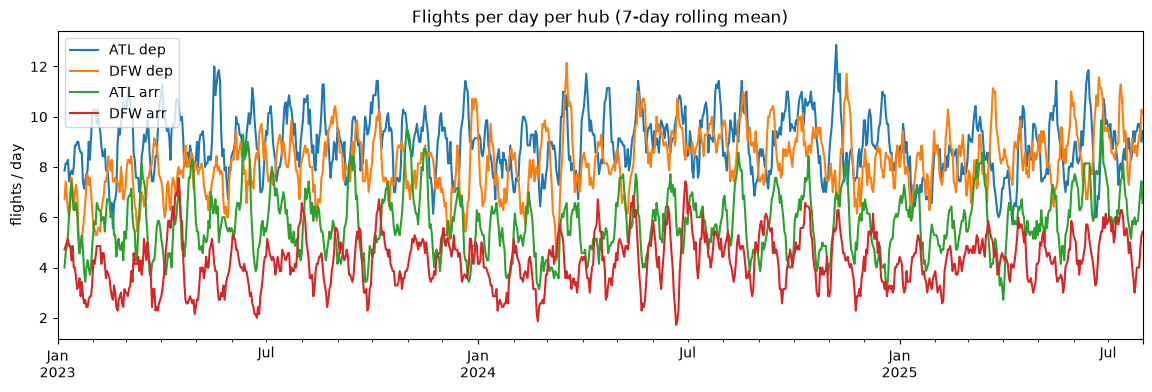

days with zero flights: {'ATL dep': 0, 'DFW dep': 0, 'ATL arr': 4, 'DFW arr': 17}


,ATL dep,DFW dep,ATL arr,DFW arr
count,943.0,943.0,943.0,943.0
mean,8.9,8.2,5.8,4.3
std,2.7,2.6,2.6,2.2
min,1.0,1.0,0.0,0.0
25%,7.0,6.0,4.0,3.0
50%,9.0,8.0,5.0,4.0
75%,11.0,10.0,7.0,6.0
max,19.0,16.0,18.0,14.0


In [16]:
daily = pd.DataFrame({
    **{f"{h} dep": flights[flights["ORIGIN"] == h].groupby("FL_DATE").size() for h in HUBS},
    **{f"{h} arr": flights[flights["DEST"] == h].groupby("FL_DATE").size() for h in HUBS},
}).reindex(all_dates).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(14, 4))
daily.rolling(7).mean().plot(ax=ax)
ax.set_title("Flights per day per hub (7-day rolling mean)")
ax.set_ylabel("flights / day")
plt.show()

print("days with zero flights:", (daily == 0).sum().to_dict())
daily.describe().round(1)

### A4. Hourly profile per hub

Flights by scheduled local hour, and how many flights fall in each airport-hour (including empty hours).

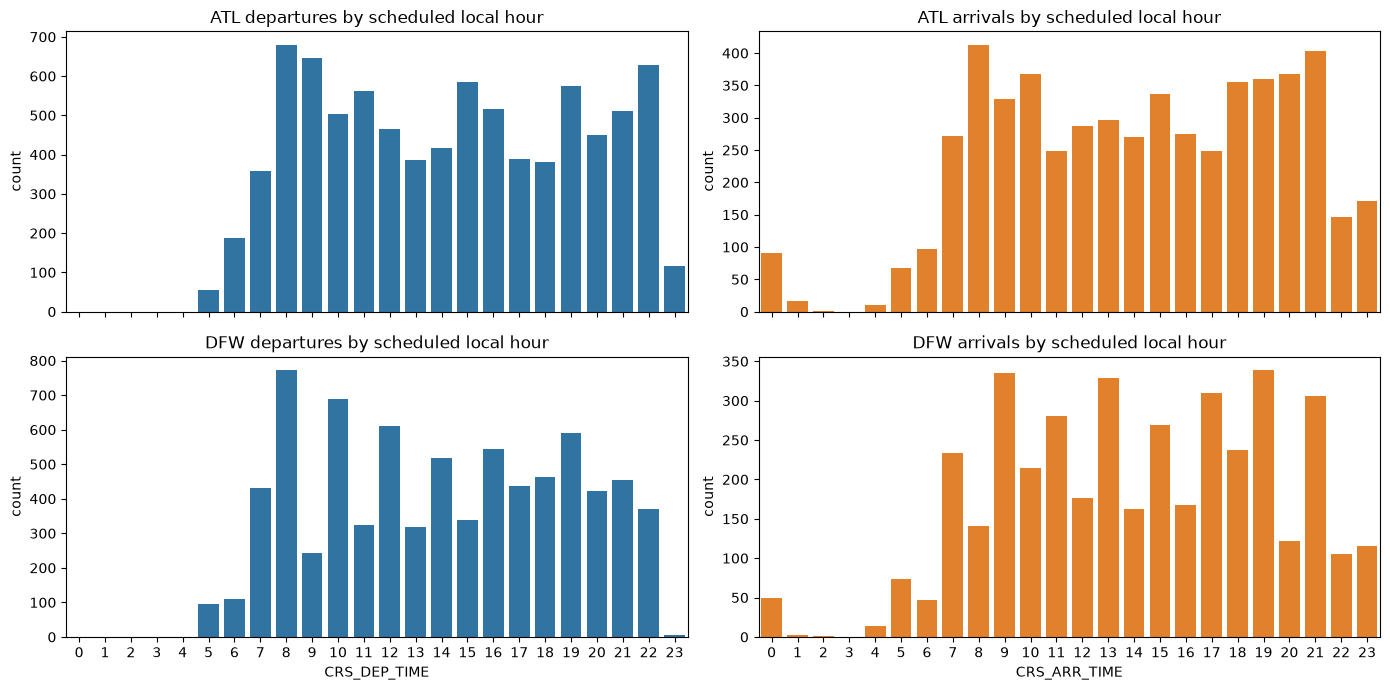

share of airport-hours with N scheduled flights:


,ATL dep,ATL arr,DFW dep,DFW arr
0,0.711,0.795,0.735,0.844
1,0.219,0.175,0.201,0.136
2,0.058,0.027,0.052,0.019
3,0.010,0.003,0.010,0.001
4,0.001,0.000,0.001,0.000
5,0.000,0.000,0.000,NaN
6,NaN,NaN,0.000,NaN


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for i, h in enumerate(HUBS):
    sns.countplot(x=hour_of(flights.loc[flights["ORIGIN"] == h, "CRS_DEP_TIME"]), order=range(24), ax=axes[i, 0], color="C0")
    sns.countplot(x=hour_of(flights.loc[flights["DEST"] == h, "CRS_ARR_TIME"]), order=range(24), ax=axes[i, 1], color="C1")
    axes[i, 0].set_title(f"{h} departures by scheduled local hour")
    axes[i, 1].set_title(f"{h} arrivals by scheduled local hour")
plt.tight_layout()
plt.show()

full_index = pd.MultiIndex.from_product([all_dates, range(24)], names=["date", "hour"])
per_hour = {}
for h in HUBS:
    for kind, col, time_col in [("dep", "ORIGIN", "CRS_DEP_TIME"), ("arr", "DEST", "CRS_ARR_TIME")]:
        sub = flights[flights[col] == h]
        counts = sub.groupby([sub["FL_DATE"], hour_of(sub[time_col])]).size()
        counts.index.names = ["date", "hour"]
        per_hour[f"{h} {kind}"] = counts.reindex(full_index, fill_value=0)
print("share of airport-hours with N scheduled flights:")
pd.DataFrame(per_hour).apply(lambda s: s.value_counts(normalize=True)).sort_index().round(3)

### A5. Date coverage

Departures + arrivals per month for each hub.

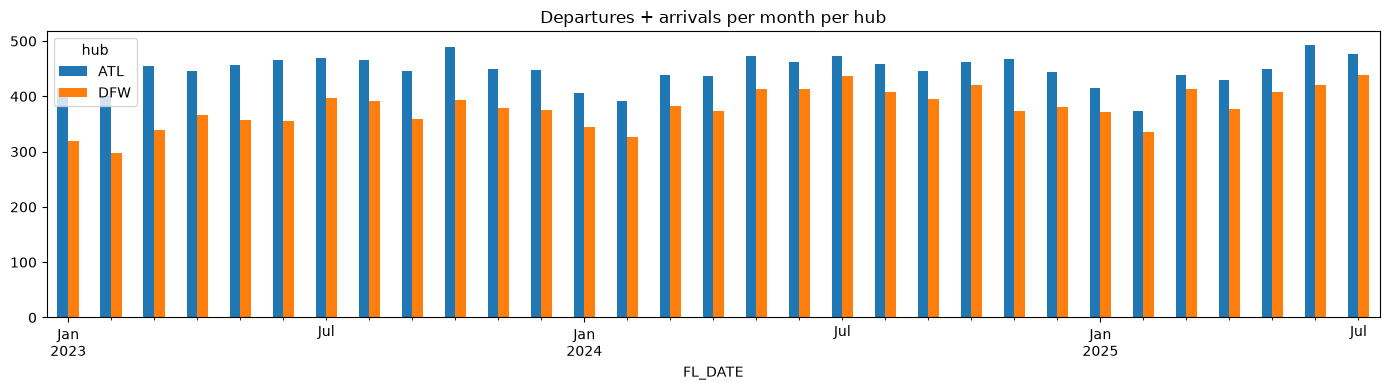

months: 31; min/max per hub per month: {'ATL': 374, 'DFW': 297} / {'ATL': 493, 'DFW': 438}


In [18]:
hub_rows = pd.concat([
    flights.loc[flights["ORIGIN"].isin(HUBS), ["FL_DATE", "ORIGIN"]].rename(columns={"ORIGIN": "hub"}),
    flights.loc[flights["DEST"].isin(HUBS), ["FL_DATE", "DEST"]].rename(columns={"DEST": "hub"}),
])
monthly = hub_rows.groupby([hub_rows["FL_DATE"].dt.to_period("M"), "hub"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(14, 4))
monthly.plot(kind="bar", ax=ax)
ax.set_title("Departures + arrivals per month per hub")
plt.tight_layout()
plt.show()
print(f"months: {len(monthly)}; min/max per hub per month: {monthly.min().to_dict()} / {monthly.max().to_dict()}")

### A6. Carrier mix at the hubs

In [19]:
carrier_rows = pd.concat([
    flights.loc[flights["ORIGIN"].isin(HUBS), ["OP_UNIQUE_CARRIER", "ORIGIN"]].rename(columns={"ORIGIN": "hub"}),
    flights.loc[flights["DEST"].isin(HUBS), ["OP_UNIQUE_CARRIER", "DEST"]].rename(columns={"DEST": "hub"}),
])
carriers = pd.crosstab(carrier_rows["OP_UNIQUE_CARRIER"], carrier_rows["hub"])
carriers["total"] = carriers.sum(axis=1)
carriers.sort_values("total", ascending=False)

hub,ATL,DFW,total
OP_UNIQUE_CARRIER,,,
DL,9308,564,9872
AA,422,7045,7467
MQ,15,1774,1789
WN,1587,0,1587
OO,299,787,1086
NK,596,434,1030
F9,484,387,871
UA,412,457,869
9E,481,0,481


## B. Targets

Main target (organizers' update): a flight at ATL/DFW is **severe** if `DEP_DELAY > 45` (departures) or `ARR_DELAY > 45` (arrivals).
We build one row per prediction target (a departure from, or an arrival into, ATL/DFW) and study the label.

### B0. One row per prediction target

Arrivals are timed at the scheduled arrival (local time at the destination). `FL_DATE` is the departure date, so overnight arrivals move to the next day.
The day shift uses the scheduled elapsed time; time-zone differences are under 12 h, so rounding gives the right day.

In [20]:
SEVERE_MIN = 45
CAUSES = ["CARRIER_DELAY", "WEATHER_DELAY", "NAS_DELAY", "SECURITY_DELAY", "LATE_AIRCRAFT_DELAY"]
CANCEL_REASONS = {"A": "airline", "B": "weather", "C": "air traffic system (NAS)", "D": "security"}

def minutes_of(hhmm: pd.Series) -> pd.Series:
    return (hhmm // 100) % 24 * 60 + hhmm % 100

KEEP = ["FL_DATE", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM", "TAIL_NUM", "ORIGIN", "DEST", "CRS_DEP_TIME", "CRS_ARR_TIME",
        "DEP_DELAY", "ARR_DELAY", "CANCELLED", "CANCELLATION_CODE", "DIVERTED", "DISTANCE",
        "temp_ORIGIN", "coco_ORIGIN", "temp_DEST", "coco_DEST"] + CAUSES

dep_t = flights.loc[flights["ORIGIN"].isin(HUBS), KEEP].copy()
dep_t["airport"], dep_t["role"] = dep_t["ORIGIN"], "departure"
dep_t["sched_date"], dep_t["sched_hhmm"] = dep_t["FL_DATE"], dep_t["CRS_DEP_TIME"]
dep_t["delay"] = dep_t["DEP_DELAY"]

arr_t = flights.loc[flights["DEST"].isin(HUBS), KEEP + ["CRS_ELAPSED_TIME"]].copy()
clock_diff = minutes_of(arr_t["CRS_ARR_TIME"]) - minutes_of(arr_t["CRS_DEP_TIME"])
day_shift = ((arr_t["CRS_ELAPSED_TIME"] - clock_diff) / 1440).round().astype(int)
arr_t["airport"], arr_t["role"] = arr_t["DEST"], "arrival"
arr_t["sched_date"] = arr_t["FL_DATE"] + pd.to_timedelta(day_shift, unit="D")
arr_t["sched_hhmm"] = arr_t["CRS_ARR_TIME"]
arr_t["delay"] = arr_t["ARR_DELAY"]
arr_t = arr_t.drop(columns="CRS_ELAPSED_TIME")

targets = pd.concat([dep_t, arr_t], ignore_index=True)
targets["sched_hour"] = hour_of(targets["sched_hhmm"])
targets["sched_local"] = targets["sched_date"] + pd.to_timedelta(minutes_of(targets["sched_hhmm"]), unit="m")
targets["month"] = targets["sched_date"].dt.month
targets["weekday"] = targets["sched_date"].dt.day_of_week + 1  # 1 = Mon
targets["severe"] = (targets["delay"] > SEVERE_MIN).where(targets["delay"].notna())
targets["group"] = targets["airport"] + " " + targets["role"]

print(f"prediction targets: {len(targets):,}")
print(f"arrivals moved to the next day: {(day_shift > 0).sum():,}")
targets.groupby(["airport", "role"]).size().unstack()

prediction targets: 25,612
arrivals moved to the next day: 386


role,arrival,departure
airport,,
ATL,5429,8415
DFW,4032,7736


### B1. Label summary

How many targets have a delay value, how many are severe, and how many were cancelled or diverted (no delay value, so they need a rule).

In [21]:
b1 = targets.groupby(["airport", "role"]).agg(
    targets=("delay", "size"),
    with_delay=("delay", "count"),
    severe=("severe", "sum"),
    severe_rate=("severe", "mean"),
    cancelled=("CANCELLED", "sum"),
    diverted=("DIVERTED", "sum"),
)
b1.loc[("all", "all"), :] = [len(targets), targets["delay"].count(), targets["severe"].sum(),
                             targets["severe"].mean(), targets["CANCELLED"].sum(), targets["DIVERTED"].sum()]
b1.astype({"targets": int, "with_delay": int, "severe": int, "cancelled": int, "diverted": int}).round(3)

targets  with_delay  severe severe_rate  cancelled  \
airport role                                                            
ATL     arrival       5429        5361     472    0.088043         52   
        departure     8415        8343     780    0.093492         74   
DFW     arrival       4032        3923     459    0.117002         94   
        departure     7736        7611     991    0.130206        130   
all     all          25612       25238    2702    0.107061        350   

                   diverted  
airport role                 
ATL     arrival          16  
        departure        26  
DFW     arrival          15  
        departure        21  
all     all              78

### B2. Delay distribution

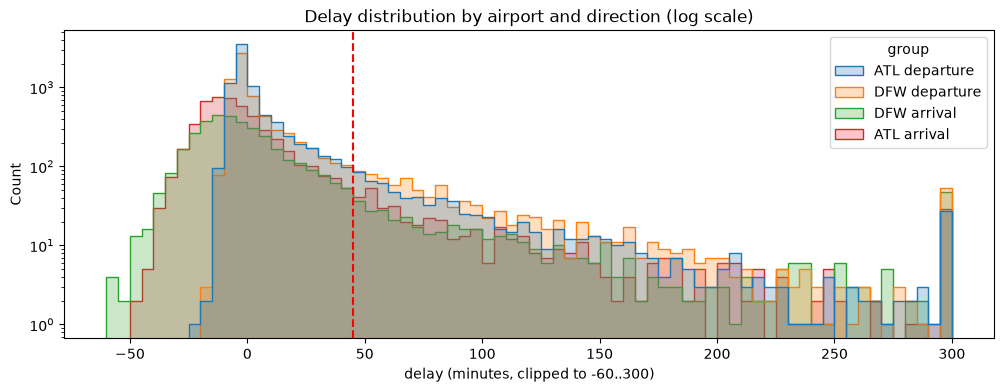

,count,mean,std,min,50%,75%,90%,95%,99%,max
group,,,,,,,,,,
ATL arrival,5361.0,6.4,53.0,-49.0,-6.0,8.0,39.0,79.0,219.0,1072.0
ATL departure,8343.0,12.4,45.7,-23.0,-1.0,10.0,42.0,81.0,186.0,1263.0
DFW arrival,3923.0,14.8,87.5,-71.0,-4.0,15.0,57.0,115.9,329.3,2103.0
DFW departure,7611.0,18.2,66.2,-20.0,-1.0,16.0,60.0,102.0,234.8,1419.0


In [22]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(data=targets, x=targets["delay"].clip(-60, 300), hue="group", bins=72, element="step", ax=ax)
ax.axvline(SEVERE_MIN, color="red", linestyle="--")
ax.set_yscale("log")
ax.set_xlabel("delay (minutes, clipped to -60..300)")
ax.set_title("Delay distribution by airport and direction (log scale)")
plt.show()
targets.groupby("group")["delay"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(1)

### B3. Cancellations and diversions

Cancellation reasons per airport and direction. These flights have no delay value.

In [23]:
cancel = pd.crosstab([targets["airport"], targets["role"]], targets["CANCELLATION_CODE"].map(CANCEL_REASONS))
cancel["diverted"] = targets.groupby(["airport", "role"])["DIVERTED"].sum().astype(int)
cancel

CANCELLATION_CODE  air traffic system (NAS)  airline  weather  diverted
airport role                                                           
ATL     arrival                           2       23       27        16
        departure                         5       30       39        26
DFW     arrival                           1       13       80        15
        departure                         5       12      113        21

### B4. When do severe delays happen?

Severe rate by scheduled local hour, day of week and month. A rate by hour and month is the simplest baseline any model has to beat.

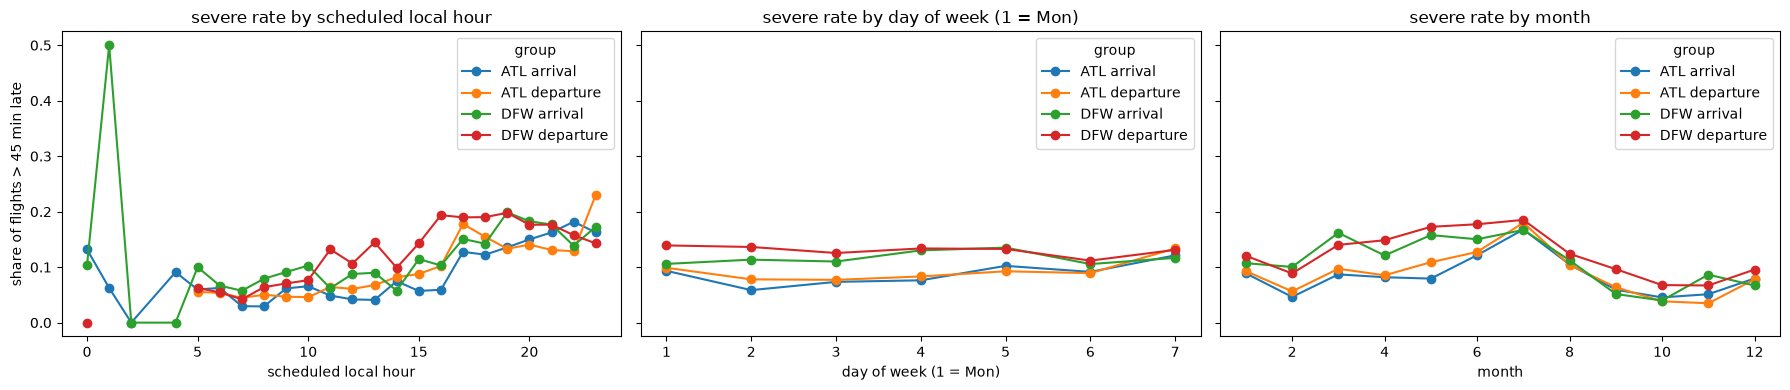

In [24]:
labelled = targets[targets["severe"].notna()].copy()
labelled["severe"] = labelled["severe"].astype(bool)

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, col, label in zip(axes, ["sched_hour", "weekday", "month"], ["scheduled local hour", "day of week (1 = Mon)", "month"]):
    labelled.groupby([col, "group"])["severe"].mean().unstack().plot(ax=ax, marker="o")
    ax.set_xlabel(label)
    ax.set_title(f"severe rate by {label}")
axes[0].set_ylabel("share of flights > 45 min late")
plt.tight_layout()
plt.show()

### B5. Delay causes

For severe flights, the split of delay minutes across causes (cause columns are filled when the flight arrived 15+ min late).
NAS (air traffic system) delays include weather-driven traffic management, so weather's true share is larger than `WEATHER_DELAY` alone.

In [25]:
severe_rows = labelled[labelled["severe"]]
print("severe flights with a cause breakdown:", severe_rows.groupby("group")["CARRIER_DELAY"].apply(lambda s: f"{s.notna().mean():.1%}").to_dict())

minutes = severe_rows.groupby("group")[CAUSES].sum()
display((minutes.div(minutes.sum(axis=1), axis=0) * 100).round(1).rename(columns=lambda c: c.replace("_DELAY", "").lower() + " %min"))
display((severe_rows.groupby("group")[CAUSES].apply(lambda g: (g > 0).mean()) * 100).round(1)
        .rename(columns=lambda c: c.replace("_DELAY", "").lower() + " %flights"))

severe flights with a cause breakdown: {'ATL arrival': '100.0%', 'ATL departure': '99.1%', 'DFW arrival': '100.0%', 'DFW departure': '99.6%'}


,carrier %min,weather %min,nas %min,security %min,late_aircraft %min
group,,,,,
ATL arrival,37.9,4.7,15.4,0.0,42.0
ATL departure,44.1,7.3,13.0,0.1,35.5
DFW arrival,25.8,10.1,15.2,0.2,48.6
DFW departure,30.1,9.5,8.7,0.1,51.6


,carrier %flights,weather %flights,nas %flights,security %flights,late_aircraft %flights
group,,,,,
ATL arrival,57.6,7.0,46.6,0.4,64.8
ATL departure,70.8,7.3,35.6,0.3,49.7
DFW arrival,48.8,15.9,52.5,0.7,62.3
DFW departure,63.5,15.1,33.3,0.3,69.6


### B6. Normalising delays across airports

The brief warns against comparing raw delay minutes. For the 20 busiest origin airports: total delay minutes (driven by volume) vs severe departure rate.

In [26]:
top20 = flights["ORIGIN"].value_counts().head(20).index
by_airport = flights[flights["ORIGIN"].isin(top20) & flights["DEP_DELAY"].notna()].groupby("ORIGIN").agg(
    departures=("DEP_DELAY", "size"),
    total_delay_minutes=("DEP_DELAY_NEW", "sum"),
    severe_rate=("DEP_DELAY", lambda s: (s > SEVERE_MIN).mean()),
)
by_airport["rank_total_minutes"] = by_airport["total_delay_minutes"].rank(ascending=False).astype(int)
by_airport["rank_severe_rate"] = by_airport["severe_rate"].rank(ascending=False).astype(int)
by_airport.sort_values("total_delay_minutes", ascending=False).round(3)

,departures,total_delay_minutes,severe_rate,rank_total_minutes,rank_severe_rate
ORIGIN,,,,,
DFW,7611,158176.0,0.130,1,2
DEN,7625,133921.0,0.115,2,7
ORD,6995,124439.0,0.115,3,8
ATL,8343,123369.0,0.093,4,16
CLT,5079,91256.0,0.119,5,5
MCO,3998,77201.0,0.125,6,3
LAS,4789,76898.0,0.103,7,11
EWR,3241,61568.0,0.116,8,6
DCA,3441,61301.0,0.101,9,12


### B7. How departure and arrival delays relate

An arrival's delay is mostly decided at its origin. For arrivals into ATL/DFW: how often was a severe arrival already a severe departure from the origin?
For departures from ATL/DFW: how often does a severe departure also arrive severely late?

In [27]:
f = flights[flights["DEP_DELAY"].notna() & flights["ARR_DELAY"].notna()]
print(f"correlation DEP_DELAY vs ARR_DELAY (all flights): {f['DEP_DELAY'].corr(f['ARR_DELAY']):.3f}")
rows = []
for h in HUBS:
    a = f[f["DEST"] == h]
    d = f[f["ORIGIN"] == h]
    rows.append({
        "airport": h,
        "severe arrivals that were severe departures": ((a["ARR_DELAY"] > 45) & (a["DEP_DELAY"] > 45)).sum() / (a["ARR_DELAY"] > 45).sum(),
        "severe departures that became severe arrivals": ((d["DEP_DELAY"] > 45) & (d["ARR_DELAY"] > 45)).sum() / (d["DEP_DELAY"] > 45).sum(),
        "median (arr delay - dep delay), min": (a["ARR_DELAY"] - a["DEP_DELAY"]).median(),
    })
pd.DataFrame(rows).set_index("airport").round(3)

correlation DEP_DELAY vs ARR_DELAY (all flights): 0.967


,severe arrivals that were severe departures,severe departures that became severe arrivals,"median (arr delay - dep delay), min"
airport,,,
ATL,0.858,0.871,-8.0
DFW,0.856,0.863,-7.0


In [28]:
# Where do arrivals into ATL/DFW come from? (their delay is mostly set at these origins)
inbound_origins = targets[targets["role"] == "arrival"].groupby(["airport", "ORIGIN"]).size()
print("distinct origins of arrivals:", targets[targets["role"] == "arrival"].groupby("airport")["ORIGIN"].nunique().to_dict())
inbound_origins.groupby(level=0, group_keys=False).nlargest(5)

distinct origins of arrivals: {'ATL': 64, 'DFW': 74}


airport  ORIGIN
ATL      MCO       219
         FLL       209
         EWR       200
         DCA       189
         MIA       185
DFW      ATL       159
         ORD       153
         SEA       149
         DEN       147
         LAS       146
dtype: int64

## C. Hourly Weather File

`challenge5_hourly_weather_ATL_DFW.csv`: completeness, units, condition codes, wind components, seasonal and daily patterns,
and how well weather now predicts weather 3-12 h later.

In [29]:
WX_NUM = ["temp_c", "dewpoint_c", "rel_humidity_pct", "precip_mm", "wind_speed_kmh", "pressure_hpa",
          "headwind_kmh", "crosswind_kmh", "tailwind_kmh"]

# Meteostat condition codes (the guide lists the main ranges; full list from Meteostat's documentation)
COCO_LABELS = {
    1: "clear", 2: "fair", 3: "cloudy", 4: "overcast", 5: "fog", 6: "freezing fog",
    7: "light rain", 8: "rain", 9: "heavy rain", 10: "freezing rain", 11: "heavy freezing rain",
    12: "sleet", 13: "heavy sleet", 14: "light snowfall", 15: "snowfall", 16: "heavy snowfall",
    17: "rain shower", 18: "heavy rain shower", 19: "sleet shower", 20: "heavy sleet shower",
    21: "snow shower", 22: "heavy snow shower", 23: "lightning", 24: "hail",
    25: "thunderstorm", 26: "heavy thunderstorm", 27: "storm",
}
WX_GROUP_ORDER = ["clear", "cloudy", "fog", "rain", "heavy rain", "snow/ice", "thunderstorm"]

def wx_group(code_) -> str | None:
    if pd.isna(code_):
        return None
    c = int(code_)
    if c <= 2: return "clear"
    if c <= 4: return "cloudy"
    if c <= 6: return "fog"
    if c in (7, 8, 17): return "rain"
    if c in (9, 18): return "heavy rain"
    if c >= 23: return "thunderstorm"
    return "snow/ice"

wx = weather.copy()
wx["wx_group"] = wx["condition_code"].map(wx_group)
wx["local_month"] = wx["time_local"].dt.month
wx["local_hour"] = wx["time_local"].dt.hour

### C1. Completeness and time stamps

Every hour present? Duplicates? Missing values? And how daylight saving shows up in `time_local` (one repeated hour in autumn, one skipped hour in spring).

In [30]:
full_utc = pd.date_range("2023-01-01", "2025-07-31 23:00", freq="h")
rows = []
for a, g in wx.groupby("airport"):
    local = g["time_local"]
    rows.append({
        "airport": a,
        "hours": len(g),
        "missing_utc_hours": len(full_utc.difference(pd.DatetimeIndex(g["time_utc"]))),
        "duplicate_utc_hours": g["time_utc"].duplicated().sum(),
        "repeated_local_hours": local.duplicated().sum(),
        "skipped_local_hours": len(pd.date_range(local.min(), local.max(), freq="h").difference(pd.DatetimeIndex(local))),
        "utc_offsets_h": sorted(((local - g["time_utc"]).dt.total_seconds() / 3600).unique().tolist()),
    })
display(pd.DataFrame(rows).set_index("airport"))
print("missing values per column:")
wx.groupby("airport")[weather.columns.drop("airport")].apply(lambda g: g.isna().sum()).T.query("ATL > 0 or DFW > 0")

,hours,missing_utc_hours,duplicate_utc_hours,repeated_local_hours,skipped_local_hours,utc_offsets_h
airport,,,,,,
ATL,22632,0,0,2,3,"[-5.0, -4.0]"
DFW,22632,0,0,2,3,"[-6.0, -5.0]"


missing values per column:


airport,ATL,DFW
precip_mm,13,40
wind_gust_kmh,22632,22632
condition_code,6,6


### C2. Distributions and units

Temperature and dew point in °C, humidity in %, precipitation in mm per hour, wind in km/h, pressure in hPa.

airport                     ATL      DFW
temp_c           count  22632.0  22632.0
                 mean      18.5     20.5
                 std        8.5      9.6
                 min      -10.0    -11.7
                 25%       12.8     13.9
                 50%       19.4     21.7
                 75%       25.0     27.8
                 max       37.2     42.8
dewpoint_c       count  22632.0  22632.0
                 mean      10.8     11.9
                 std        9.1      9.2
                 min      -20.7    -20.1
                 25%        3.5      4.9
                 50%       13.4     14.4
                 75%       18.3     19.7
                 max       25.1     26.7
rel_humidity_pct count  22632.0  22632.0
                 mean      63.9     61.2
                 std       19.2     19.6
                 min       15.0      8.0
                 25%       49.0     46.0
                 50%       64.0     61.0
                 75%       81.0     77.0
                 max      100.0    100.0
precip_mm        count  22619.0  22592.0
                 mean       0.2      0.1
                 std        1.1      0.9
                 min        0.0      0.0
                 25%        0.0      0.0
                 50%        0.0      0.0
                 75%        0.0      0.0
                 max       62.5     37.6
wind_speed_kmh   count  22632.0  22632.0
                 mean      12.9     16.5
                 std        7.0      8.6
                 min        0.0      0.0
                 25%        7.6     11.2
                 50%       13.0     14.8
                 75%       16.6     22.3
                 max       86.4     83.0
pressure_hpa     count  22632.0  22632.0
                 mean    1017.6   1014.9
                 std        5.6      6.6
                 min      985.3    991.1
                 25%     1013.9   1010.7
                 50%     1017.4   1014.1
                 75%     1020.8   1018.3
                 max     1038.9   1041.4
headwind_kmh     count  22632.0  22632.0
                 mean      -1.7      5.1
                 std       11.0     15.5
                 min      -55.5    -78.0
                 25%       -9.3     -6.3
                 50%       -3.8      7.2
                 75%        5.7     16.6
                 max       51.0     51.8
crosswind_kmh    count  22632.0  22632.0
                 mean       7.3      6.8
                 std        6.2      5.7
                 min        0.0      0.0
                 25%        2.7      2.9
                 50%        6.0      5.7
                 75%       10.7      9.7
                 max       66.2     55.1
tailwind_kmh     count  22632.0  22632.0
                 mean       5.4      4.3
                 std        6.4      7.9
                 min        0.0      0.0
                 25%        0.0      0.0
                 50%        3.8      0.0
                 75%        9.3      6.3
                 max       55.5     78.0

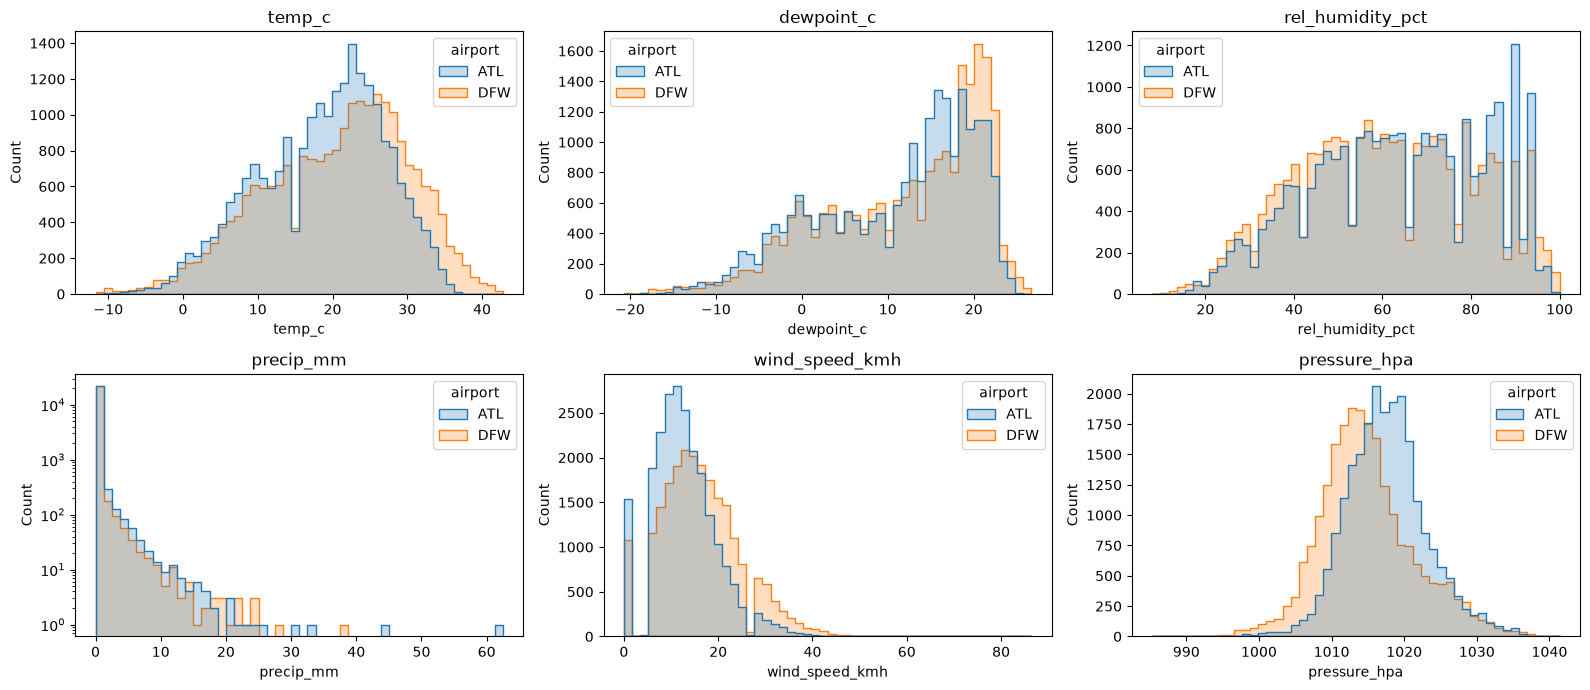

In [31]:
display(wx.groupby("airport")[WX_NUM].describe().T.round(1))

fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.flat, ["temp_c", "dewpoint_c", "rel_humidity_pct", "precip_mm", "wind_speed_kmh", "pressure_hpa"]):
    sns.histplot(data=wx, x=col, hue="airport", bins=50, element="step", ax=ax)
    if col == "precip_mm":
        ax.set_yscale("log")
    ax.set_title(col)
plt.tight_layout()
plt.show()

### C3. Condition codes

In [32]:
codes = wx.groupby(["condition_code", "airport"]).size().unstack(fill_value=0)
codes.index = [f"{int(c)}: {COCO_LABELS.get(int(c), '?')} -> {wx_group(c)}" for c in codes.index]
display(codes)
print("hours per weather group (share):")
(wx.groupby("airport")["wx_group"].value_counts(normalize=True).unstack(0).reindex(WX_GROUP_ORDER) * 100).round(2)

airport,ATL,DFW
1: clear -> clear,3469,2768
2: fair -> clear,7896,8334
3: cloudy -> cloudy,5459,4843
4: overcast -> cloudy,2339,4129
5: fog -> fog,671,534
7: light rain -> rain,1294,709
8: rain -> rain,889,699
9: heavy rain -> heavy rain,420,201
10: freezing rain -> snow/ice,2,30
11: heavy freezing rain -> snow/ice,0,8


hours per weather group (share):


airport,ATL,DFW
wx_group,,
clear,50.23,49.07
cloudy,34.46,39.65
fog,2.97,2.36
rain,9.65,6.24
heavy rain,2.43,2.09
snow/ice,0.05,0.31
thunderstorm,0.20,0.28


### C4. Wind direction and runway components

Direction distribution (30° sectors), calm hours, rows with speed but direction 0, and a check that the provided components follow the stated formulas.

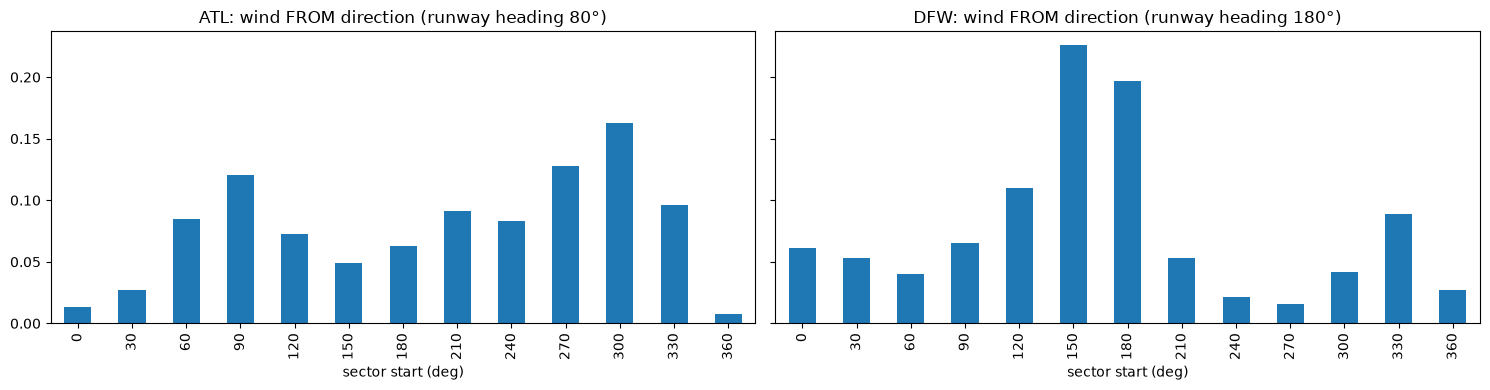

max difference between recomputed and provided components (km/h): {'headwind': 0.05, 'crosswind': 0.05, 'tailwind': 0.0}
calm hours (speed 0): {'ATL': '6.8%', 'DFW': '4.7%'}
hours with speed > 0 but direction 0: 57 (by airport: {'ATL': 30, 'DFW': 27})
share of hours with any tailwind: {'ATL': '57.0%', 'DFW': '30.8%'}


,airport,runway_heading_deg,time_utc,time_local,temp_c,dewpoint_c,rel_humidity_pct,precip_mm,wind_dir_deg,wind_speed_kmh,wind_gust_kmh,pressure_hpa,condition_code,headwind_kmh,crosswind_kmh,tailwind_kmh,wx_group,local_month,local_hour
355,ATL,80,2023-01-15 19:00:00,2023-01-15 14:00:00,13.3,-8.0,22,0.0,0,5.4,NaN,1020.4,2.0,0.9,5.3,0.0,clear,1,14
924,ATL,80,2023-02-08 12:00:00,2023-02-08 07:00:00,13.3,6.6,64,0.0,0,5.4,NaN,1025.0,4.0,0.9,5.3,0.0,cloudy,2,7
2107,ATL,80,2023-03-29 19:00:00,2023-03-29 15:00:00,17.2,-2.0,27,0.0,0,7.6,NaN,1022.1,2.0,1.3,7.5,0.0,clear,3,15
2293,ATL,80,2023-04-06 13:00:00,2023-04-06 09:00:00,22.8,18.3,76,0.0,0,5.4,NaN,1023.3,3.0,0.9,5.3,0.0,cloudy,4,9
3185,ATL,80,2023-05-13 17:00:00,2023-05-13 13:00:00,27.2,19.0,61,0.0,0,5.4,NaN,1019.6,3.0,0.9,5.3,0.0,cloudy,5,13


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, (a, g) in zip(axes, wx.groupby("airport")):
    moving = g[g["wind_speed_kmh"] > 0]
    sectors = (moving["wind_dir_deg"] // 30 * 30).value_counts(normalize=True).sort_index()
    sectors.plot(kind="bar", ax=ax)
    heading = g["runway_heading_deg"].iloc[0]
    ax.set_title(f"{a}: wind FROM direction (runway heading {heading}°)")
    ax.set_xlabel("sector start (deg)")
plt.tight_layout()
plt.show()

angle = np.deg2rad(wx["wind_dir_deg"] - wx["runway_heading_deg"])
check = pd.DataFrame({
    "headwind": (wx["wind_speed_kmh"] * np.cos(angle) - wx["headwind_kmh"]).abs(),
    "crosswind": (np.abs(wx["wind_speed_kmh"] * np.sin(angle)) - wx["crosswind_kmh"]).abs(),
    "tailwind": (np.maximum(-wx["headwind_kmh"], 0) - wx["tailwind_kmh"]).abs(),
})
print("max difference between recomputed and provided components (km/h):", check.max().round(2).to_dict())
print("calm hours (speed 0):", wx.groupby("airport")["wind_speed_kmh"].apply(lambda s: f"{(s == 0).mean():.1%}").to_dict())
odd = wx[(wx["wind_dir_deg"] == 0) & (wx["wind_speed_kmh"] > 0)]
print(f"hours with speed > 0 but direction 0: {len(odd)} (by airport: {odd['airport'].value_counts().to_dict()})")
print("share of hours with any tailwind:", wx.groupby("airport")["tailwind_kmh"].apply(lambda s: f"{(s > 0).mean():.1%}").to_dict())
odd.head()

### C5. Seasonal and daily patterns

By local month and local hour: share of hours with rain, share with thunderstorms, and mean crosswind / tailwind.

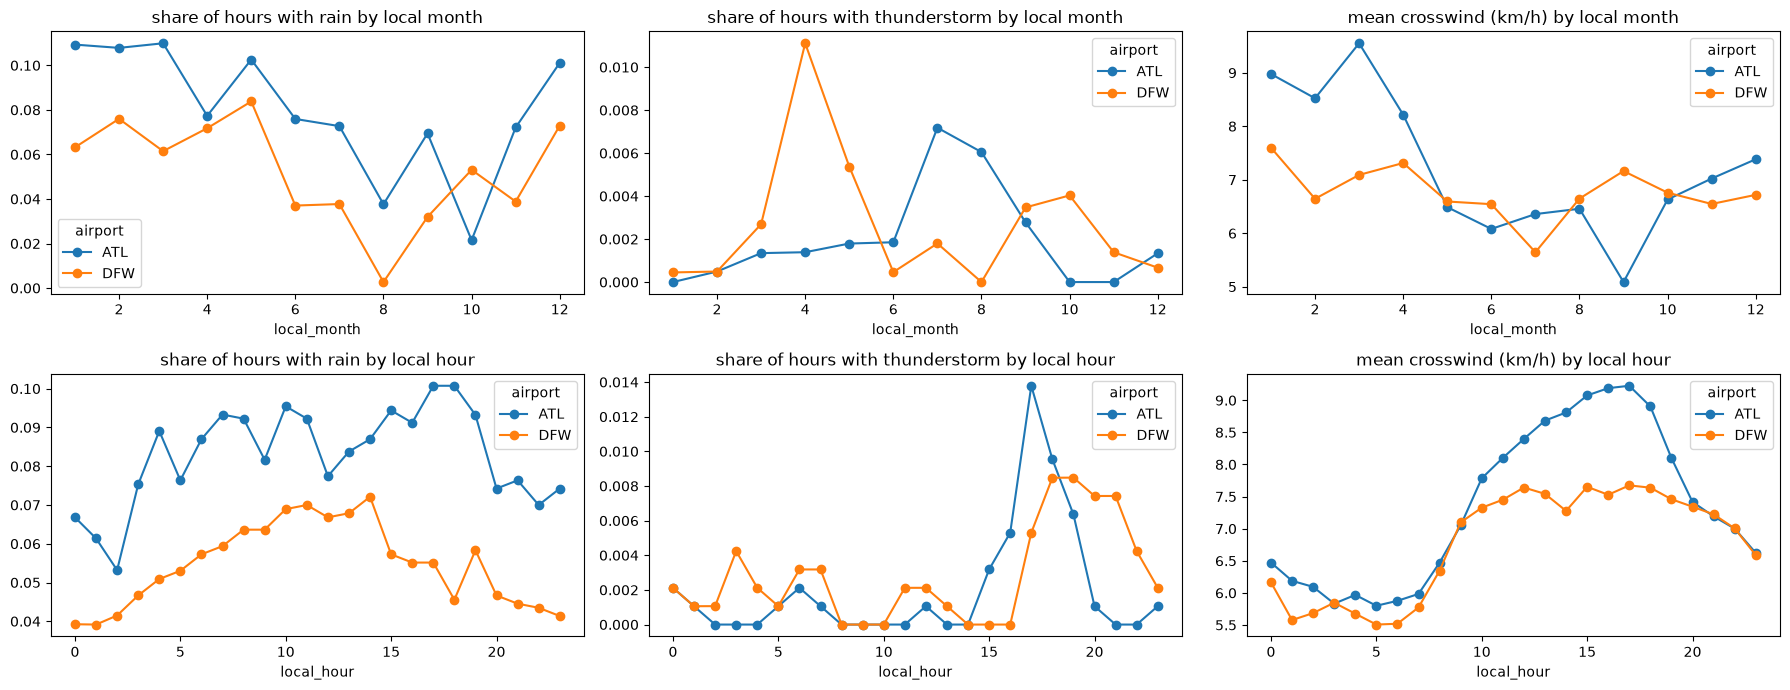

In [34]:
wx["rain_any"] = wx["precip_mm"] > 0
wx["thunder"] = wx["wx_group"] == "thunderstorm"

fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for row, col in enumerate(["local_month", "local_hour"]):
    for ax, (var, title) in zip(axes[row], [("rain_any", "share of hours with rain"),
                                            ("thunder", "share of hours with thunderstorm"),
                                            ("crosswind_kmh", "mean crosswind (km/h)")]):
        wx.groupby([col, "airport"])[var].mean().unstack().plot(ax=ax, marker="o")
        ax.set_title(f"{title} by {col.replace('_', ' ')}")
plt.tight_layout()
plt.show()

### C6. How predictable is weather 3-12 h ahead from observations alone?

Under the 3-hour rule, a model only sees weather from 3-12 h before the flight. How much does weather then tell us about weather at flight time?
- numeric variables: correlation between the value at time t and at t - lag
- events (rain, thunderstorm, heavy rain or thunderstorm): chance of the event at t given it was present at t - lag, vs its base rate

In [35]:
LAGS = [3, 6, 9, 12]
wx = wx.sort_values(["airport", "time_utc"]).reset_index(drop=True)
wx["severe_wx"] = wx["wx_group"].isin(["heavy rain", "thunderstorm", "snow/ice"])

auto = {}
cond = []
for a, g in wx.groupby("airport"):
    g = g.set_index("time_utc")
    for lag in LAGS:
        past = g.shift(lag, freq="h").reindex(g.index)
        auto[(a, lag)] = {v: g[v].corr(past[v]) for v in ["temp_c", "pressure_hpa", "rel_humidity_pct", "wind_speed_kmh", "crosswind_kmh", "tailwind_kmh"]}
        for ev in ["rain_any", "thunder", "severe_wx"]:
            was = past[ev].astype("boolean")
            cond.append({"airport": a, "lag_h": lag, "event": ev, "base_rate": g[ev].mean(),
                         "rate_if_present_lag_ago": g.loc[was.fillna(False).to_numpy(), ev].mean()})

print("correlation of each variable with itself `lag` hours earlier")
display(pd.DataFrame(auto).T.round(2))
cond = pd.DataFrame(cond)
cond["lift"] = cond["rate_if_present_lag_ago"] / cond["base_rate"]
cond.pivot_table(index=["event", "lag_h"], columns="airport", values=["base_rate", "rate_if_present_lag_ago", "lift"]).round(3)

correlation of each variable with itself `lag` hours earlier


temp_c  pressure_hpa  rel_humidity_pct  wind_speed_kmh  crosswind_kmh  \
ATL 3     0.94          0.97              0.83            0.64           0.58   
    6     0.84          0.93              0.55            0.46           0.43   
    9     0.75          0.90              0.30            0.32           0.32   
    12    0.71          0.86              0.18            0.24           0.25   
DFW 3     0.95          0.97              0.83            0.66           0.49   
    6     0.86          0.93              0.55            0.51           0.32   
    9     0.78          0.89              0.31            0.40           0.22   
    12    0.75          0.85              0.19            0.31           0.16   

        tailwind_kmh  
ATL 3           0.71  
    6           0.57  
    9           0.47  
    12          0.40  
DFW 3           0.80  
    6           0.69  
    9           0.58  
    12          0.49

base_rate           lift         rate_if_present_lag_ago  \
airport               ATL    DFW     ATL     DFW                     ATL   
event     lag_h                                                            
rain_any  3         0.083  0.054   6.245   8.619                   0.517   
          6         0.083  0.054   4.613   5.761                   0.382   
          9         0.083  0.054   3.626   4.034                   0.300   
          12        0.083  0.054   3.039   3.141                   0.252   
severe_wx 3         0.027  0.027  16.680  14.742                   0.448   
          6         0.027  0.027  10.057   8.292                   0.270   
          9         0.027  0.027   7.064   5.835                   0.190   
          12        0.027  0.027   5.098   4.730                   0.137   
thunder   3         0.002  0.003  10.696  45.618                   0.022   
          6         0.002  0.003   0.000   5.702                   0.000   
          9         0.002  0.003   0.000   0.000                   0.000   
          12        0.002  0.003   0.000   0.000                   0.000   

                        
airport            DFW  
event     lag_h         
rain_any  3      0.470  
          6      0.314  
          9      0.220  
          12     0.171  
severe_wx 3      0.395  
          6      0.222  
          9      0.157  
          12     0.127  
thunder   3      0.127  
          6      0.016  
          9      0.000  
          12     0.000

## D. Joining Weather to Flights

Flight times are local; the hourly file has both UTC and local hours. Joining on **UTC** avoids the daylight-saving problems in local time (C1).
Then: check how the weather already inside the flights file was timed, and build the 3-12 h lookback weather that the 3-hour rule allows.

### D1. Time-zone-safe scheduled time

Convert each target's scheduled local time to UTC with the airport's time zone.
Times in the repeated autumn hour are ambiguous; times in the skipped spring hour are moved forward.

**Assumption:** time zones for ATL/DFW are set by hand. The any-airport pipeline will need a time zone per airport (e.g. from a public airport database).

In [36]:
targets["sched_utc"] = pd.NaT
for a, tz in HUB_TZ.items():
    m = targets["airport"] == a
    targets.loc[m, "sched_utc"] = (
        targets.loc[m, "sched_local"].dt.tz_localize(tz, ambiguous="NaT", nonexistent="shift_forward")
        .dt.tz_convert("UTC").dt.tz_localize(None)
    )
targets["sched_utc"] = pd.to_datetime(targets["sched_utc"])
targets = targets.reset_index(drop=True)
targets["target_id"] = targets.index

print(f"targets with an ambiguous local time (repeated autumn hour): {targets['sched_utc'].isna().sum()}")
print("UTC offset used (hours):", ((targets["sched_local"] - targets["sched_utc"]).dt.total_seconds() / 3600)
      .groupby(targets["airport"]).value_counts().to_dict())

targets with an ambiguous local time (repeated autumn hour): 0
UTC offset used (hours): {('ATL', -4.0): 9324, ('ATL', -5.0): 4520, ('DFW', -5.0): 8027, ('DFW', -6.0): 3741}


### D2. How was the weather inside the flights file timed?

The flights file's weather columns (`*_ORIGIN` for departures, `*_DEST` for arrivals) were attached by the organizers.
Compare them with the hourly file under different readings of the flight's scheduled hour:
- **true time:** the hour the flight was actually scheduled (via UTC), shifted by -6..+2 h
- **clock hour read as UTC:** the flight's local clock hour (on `FL_DATE`) looked up as if it were a UTC hour

Agreement = condition code identical and temperature within 0.1 °C.

In [37]:
wx_by_utc = wx.set_index(["airport", "time_utc"])[["temp_c", "condition_code"]]

def agreement(keys: pd.DataFrame, temp: pd.Series, coco: pd.Series) -> float:
    found = wx_by_utc.reindex(pd.MultiIndex.from_frame(keys))
    ok = found["temp_c"].notna().to_numpy()
    same = np.isclose(found["temp_c"].to_numpy()[ok], temp.to_numpy()[ok], atol=0.1) & (found["condition_code"].to_numpy()[ok] == coco.to_numpy()[ok])
    return same.mean()

rows = []
for role, prefix, time_col in [("departure", "ORIGIN", "CRS_DEP_TIME"), ("arrival", "DEST", "CRS_ARR_TIME")]:
    t = targets[(targets["role"] == role) & targets["sched_utc"].notna()]
    temp, coco = t[f"temp_{prefix}"], t[f"coco_{prefix}"]
    for shift in range(-6, 3):
        keys = pd.DataFrame({"airport": t["airport"], "time_utc": t["sched_utc"].dt.floor("h") + pd.Timedelta(hours=shift)})
        rows.append({"role": role, "reading": f"true time {shift:+d} h", "agreement": agreement(keys, temp, coco)})
    keys = pd.DataFrame({"airport": t["airport"], "time_utc": t["FL_DATE"] + pd.to_timedelta(hour_of(t[time_col]), unit="h")})
    rows.append({"role": role, "reading": "clock hour read as UTC", "agreement": agreement(keys, temp, coco)})

timing = pd.DataFrame(rows).pivot(index="reading", columns="role", values="agreement")
timing.sort_values("departure", ascending=False).round(3)

role,arrival,departure
reading,,
clock hour read as UTC,0.446,0.445
true time -5 h,0.422,0.434
true time -6 h,0.374,0.410
true time -4 h,0.227,0.223
true time -3 h,0.079,0.075
true time -2 h,0.045,0.043
true time -1 h,0.031,0.030
true time +0 h,0.021,0.024
true time +1 h,0.016,0.015


### D3. Lookback weather allowed by the 3-hour rule

For each target and lookback L (3, 6, 9, 12 h): the latest hourly observation at or before `scheduled UTC - L`.
L = 0 (weather in the hour of the flight) is kept **only as a reference** in later sections: it is leakage and cannot be a model input.

In [38]:
LOOKBACKS = [0, 3, 6, 9, 12]
LAG_COLS = ["temp_c", "dewpoint_c", "rel_humidity_pct", "precip_mm", "wind_speed_kmh", "pressure_hpa",
            "headwind_kmh", "crosswind_kmh", "tailwind_kmh", "condition_code", "wx_group"]
wx_lookup = wx.set_index(["airport", "time_utc"])[LAG_COLS]

parts = []
base = targets.loc[targets["sched_utc"].notna(), ["target_id", "airport", "role", "group", "sched_utc", "sched_hour",
                                                  "month", "delay", "severe", "CANCELLATION_CODE"]]
for L in LOOKBACKS:
    obs_time = (base["sched_utc"] - pd.Timedelta(hours=L)).dt.floor("h")
    found = wx_lookup.reindex(pd.MultiIndex.from_arrays([base["airport"], obs_time])).reset_index(drop=True)
    part = pd.concat([base.reset_index(drop=True), found], axis=1)
    part["lookback"] = L
    part["obs_time"] = obs_time.to_numpy()
    parts.append(part)
lagged = pd.concat(parts, ignore_index=True)

print("share of targets with weather found at each lookback:")
lagged.groupby(["lookback", "group"])["temp_c"].apply(lambda s: s.notna().mean()).unstack().round(4)

share of targets with weather found at each lookback:


group,ATL arrival,ATL departure,DFW arrival,DFW departure
lookback,,,,
0,0.9998,0.9999,0.9998,0.9999
3,1.0000,1.0000,1.0000,1.0000
6,1.0000,1.0000,1.0000,1.0000
9,1.0000,1.0000,1.0000,1.0000
12,1.0000,0.9999,1.0000,1.0000


### D4. Window features over the allowed 3-12 h window

Single-hour lookbacks can miss a storm that came and went. Summaries over every hour from 12 h to 3 h before the scheduled time:
max precipitation, any rain / heavy weather / thunderstorm, max wind, crosswind and tailwind, and the pressure change across the window.

In [39]:
win_parts = []
for a, g in wx.groupby("airport"):
    g = g.set_index("time_utc").sort_index()
    r = pd.DataFrame(index=g.index)
    r["win_max_precip"] = g["precip_mm"].rolling(10, min_periods=1).max()
    r["win_any_rain"] = g["rain_any"].astype(float).rolling(10).max()
    r["win_any_severe_wx"] = g["severe_wx"].astype(float).rolling(10).max()
    r["win_any_thunder"] = g["thunder"].astype(float).rolling(10).max()
    r["win_max_wind"] = g["wind_speed_kmh"].rolling(10).max()
    r["win_max_crosswind"] = g["crosswind_kmh"].rolling(10).max()
    r["win_max_tailwind"] = g["tailwind_kmh"].rolling(10).max()
    r["win_pressure_change"] = g["pressure_hpa"] - g["pressure_hpa"].shift(9)
    r["airport"] = a
    win_parts.append(r.reset_index())
windows = pd.concat(win_parts).set_index(["airport", "time_utc"])

latest_allowed = (base["sched_utc"] - pd.Timedelta(hours=3)).dt.floor("h")
window_feats = windows.reindex(pd.MultiIndex.from_arrays([base["airport"], latest_allowed])).reset_index(drop=True)
window_feats = pd.concat([base.reset_index(drop=True), window_feats], axis=1)
print("window features found:", f"{window_feats['win_max_wind'].notna().mean():.2%}")
window_feats.filter(like="win_").describe().T.round(2)

window features found: 100.00%


,count,mean,std,min,25%,50%,75%,max
win_max_precip,25602.0,0.67,2.69,0.0,0.0,0.0,0.0,62.5
win_any_rain,25611.0,0.19,0.39,0.0,0.0,0.0,0.0,1.0
win_any_severe_wx,25611.0,0.08,0.27,0.0,0.0,0.0,0.0,1.0
win_any_thunder,25611.0,0.01,0.11,0.0,0.0,0.0,0.0,1.0
win_max_wind,25611.0,20.54,8.12,0.0,14.8,18.4,25.9,86.4
win_max_crosswind,25611.0,12.53,6.22,0.0,8.2,11.3,15.6,66.2
win_max_tailwind,25611.0,8.64,9.38,0.0,0.0,7.2,14.4,78.0
win_pressure_change,25611.0,-0.04,2.79,-19.1,-1.8,0.1,1.6,22.1


### D5. Leakage check

Every lookback observation used as an input (L >= 3) must be at least 3 h before the scheduled time.

In [40]:
inputs = lagged[lagged["lookback"] >= 3]
gap_h = (inputs["sched_utc"] - inputs["obs_time"]).dt.total_seconds() / 3600
print(f"minimum gap between observation and scheduled time (L >= 3): {gap_h.min():.2f} h")
print(f"rows violating the 3-hour rule: {(gap_h < 3).sum()}")

minimum gap between observation and scheduled time (L >= 3): 3.00 h
rows violating the 3-hour rule: 0


## E. Weather vs Delays

Does weather observed 3-12 h before a flight's scheduled time relate to severe delays at ATL/DFW?
Lookback 0 (weather in the flight's own hour) is shown only as a reference: it is leakage.

In [41]:
lab = lagged[lagged["severe"].notna()].copy()
lab["severe"] = lab["severe"].astype(bool)
overall = lab[lab["lookback"] == 3].groupby("group")["severe"].mean()

# baseline: typical severe rate for the same airport + direction, scheduled hour and month
baseline = lab[lab["lookback"] == 3].groupby(["group", "sched_hour", "month"])["severe"].mean().rename("baseline")
lab = lab.join(baseline, on=["group", "sched_hour", "month"])
lab["excess"] = lab["severe"].astype(float) - lab["baseline"]

def rate_by(data: pd.DataFrame, col: str, order=None) -> pd.DataFrame:
    t = data.groupby([col, "group"], observed=True)["severe"].agg(["size", "mean"]).unstack("group")
    t.columns = [f"{g} {'n' if s == 'size' else 'rate'}" for s, g in t.columns]
    t = t[sorted(t.columns, key=lambda c: (c.rsplit(" ", 1)[0], c.endswith("rate")))]
    return t.reindex([o for o in order if o in t.index]) if order else t

### E1. Severe rate by weather group, 3 h before

Weather group of the observation 3 h before the scheduled time (with counts; small groups are unreliable).

In [42]:
display(rate_by(lab[lab["lookback"] == 3], "wx_group", WX_GROUP_ORDER).round(3))
print("overall severe rate:", overall.round(3).to_dict())

,ATL arrival n,ATL arrival rate,ATL departure n,ATL departure rate,DFW arrival n,DFW arrival rate,DFW departure n,DFW departure rate
wx_group,,,,,,,,
clear,2613,0.068,4001,0.068,1901,0.094,3670,0.100
cloudy,1902,0.098,2968,0.093,1588,0.121,3142,0.139
fog,175,0.080,303,0.102,90,0.122,193,0.140
rain,517,0.137,813,0.192,270,0.204,454,0.220
heavy rain,133,0.113,227,0.154,67,0.299,127,0.394
snow/ice,3,0.667,1,1.000,2,0.500,6,0.167
thunderstorm,15,0.333,27,0.296,5,0.400,17,0.412


overall severe rate: {'ATL arrival': 0.088, 'ATL departure': 0.093, 'DFW arrival': 0.117, 'DFW departure': 0.13}


### E2. Severe rate by weather variable bands, 3 h before

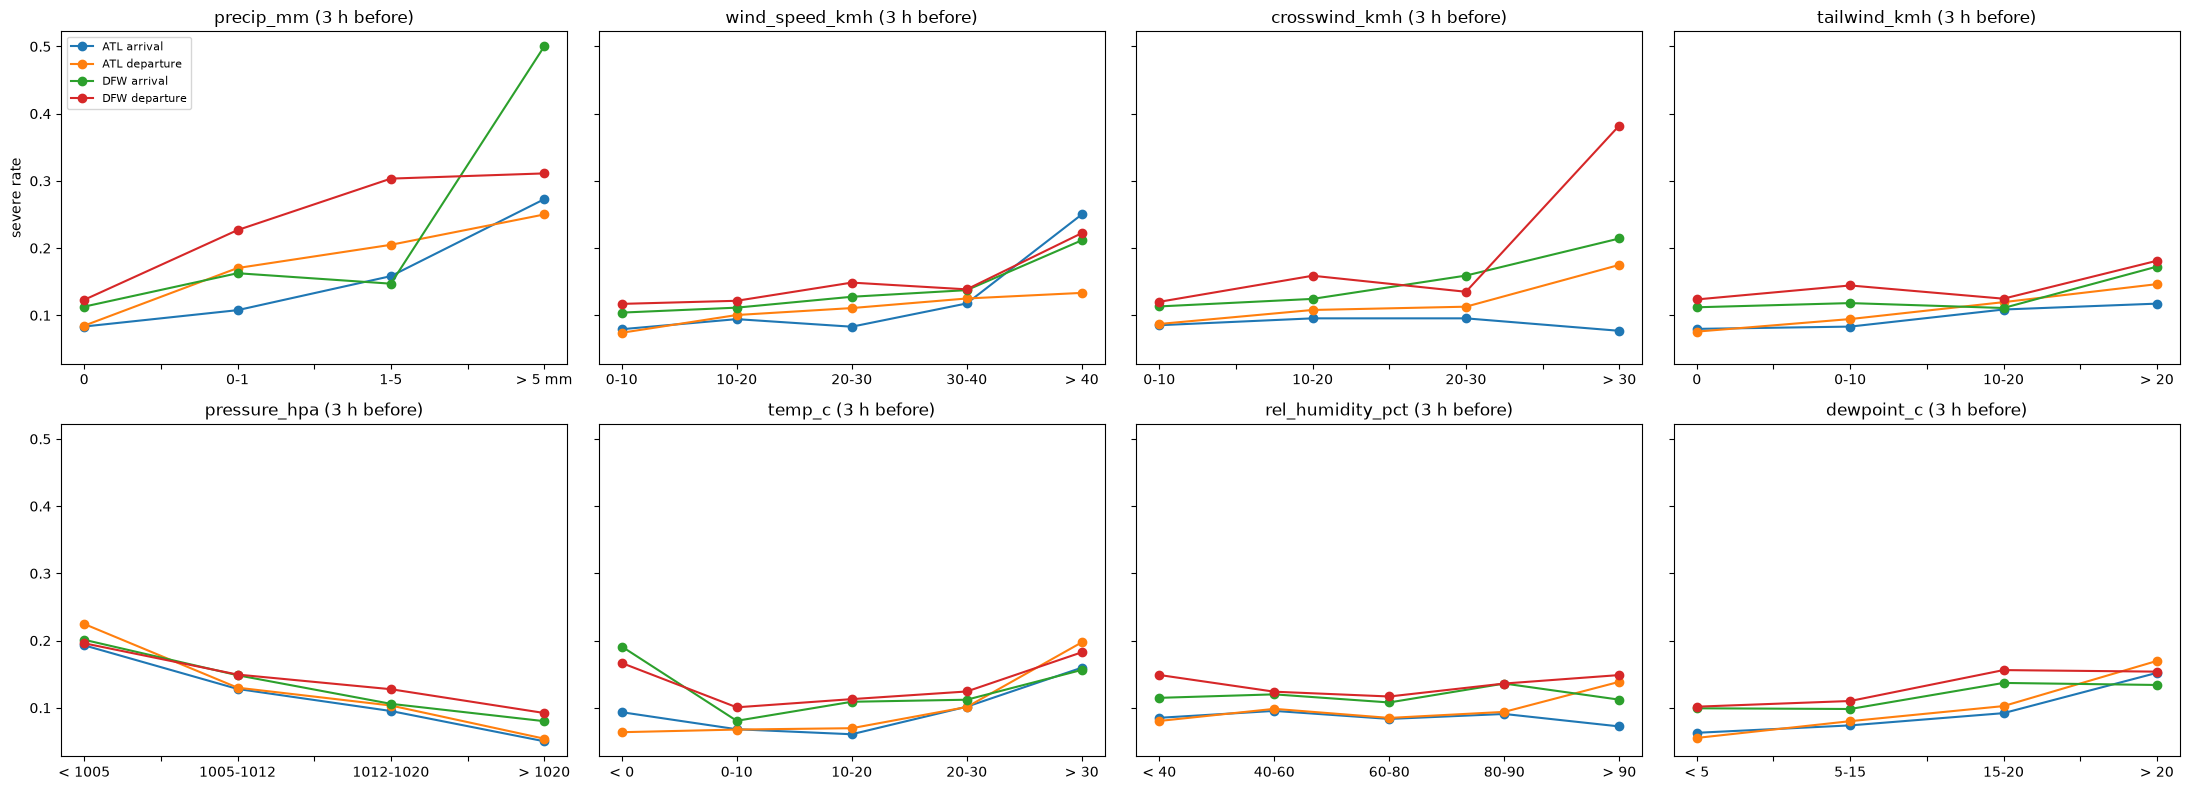

spread of severe rate across bands with 100+ targets (max - min):


group,ATL arrival,ATL departure,DFW arrival,DFW departure
precip_mm,0.189,0.165,0.387,0.188
wind_speed_kmh,0.171,0.059,0.108,0.105
crosswind_kmh,0.019,0.088,0.101,0.262
tailwind_kmh,0.038,0.071,0.062,0.058
pressure_hpa,0.143,0.171,0.121,0.104
temp_c,0.099,0.134,0.111,0.082
rel_humidity_pct,0.023,0.058,0.028,0.032
dewpoint_c,0.089,0.115,0.039,0.054


In [43]:
BANDS = {
    "precip_mm": ([-0.1, 0, 1, 5, np.inf], ["0", "0-1", "1-5", "> 5 mm"]),
    "wind_speed_kmh": ([-0.1, 10, 20, 30, 40, np.inf], ["0-10", "10-20", "20-30", "30-40", "> 40"]),
    "crosswind_kmh": ([-0.1, 10, 20, 30, np.inf], ["0-10", "10-20", "20-30", "> 30"]),
    "tailwind_kmh": ([-0.1, 0, 10, 20, np.inf], ["0", "0-10", "10-20", "> 20"]),
    "pressure_hpa": ([0, 1005, 1012, 1020, np.inf], ["< 1005", "1005-1012", "1012-1020", "> 1020"]),
    "temp_c": ([-np.inf, 0, 10, 20, 30, np.inf], ["< 0", "0-10", "10-20", "20-30", "> 30"]),
    "rel_humidity_pct": ([0, 40, 60, 80, 90, 101], ["< 40", "40-60", "60-80", "80-90", "> 90"]),
    "dewpoint_c": ([-np.inf, 5, 15, 20, np.inf], ["< 5", "5-15", "15-20", "> 20"]),
}
l3 = lab[lab["lookback"] == 3].copy()
fig, axes = plt.subplots(2, 4, figsize=(22, 8), sharey=True)
spread = {}
for ax, (var, (bins, labels)) in zip(axes.flat, BANDS.items()):
    l3[f"{var}_band"] = pd.cut(l3[var], bins, labels=labels)
    rates = l3.groupby([f"{var}_band", "group"], observed=True)["severe"].mean().unstack()
    rates.plot(ax=ax, marker="o", legend=False)
    ax.set_title(f"{var} (3 h before)")
    ax.set_xlabel("")
    counts = l3[f"{var}_band"].value_counts()
    big = counts[counts >= 100].index  # only bands with 100+ targets
    spread[var] = (rates.loc[rates.index.isin(big)].max() - rates.loc[rates.index.isin(big)].min()).round(3)
axes[0, 0].set_ylabel("severe rate")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("spread of severe rate across bands with 100+ targets (max - min):")
pd.DataFrame(spread).T

### E3. How the signal fades with lookback

**Lift** = severe rate when the weather group was observed L hours before / overall rate. 1.0 = no effect. L = 0 is the leaky reference.

lift by lookback (both directions)


wx_group          clear  cloudy   fog  rain  heavy rain  snow/ice  \
airport lookback                                                    
ATL     0          0.79    1.05  1.00  1.52        1.81      6.57   
        3          0.75    1.04  1.03  1.87        1.52      8.21   
        6          0.77    1.07  1.13  1.68        1.81       NaN   
        9          0.76    1.09  1.45  1.73        1.57     10.95   
        12         0.80    1.09  1.85  1.33        1.44      5.47   
DFW     0          0.81    1.09  0.79  1.46        2.36      2.17   
        3          0.78    1.06  1.07  1.70        2.87      1.99   
        6          0.80    1.01  1.08  1.87        2.76      1.77   
        9          0.80    1.07  1.15  1.82        2.35      0.72   
        12         0.79    1.14  1.35  1.69        1.47      1.87   

wx_group          thunderstorm  
airport lookback                
ATL     0                 3.32  
        3                 3.39  
        6                 2.88  
        9                 0.00  
        12                0.68  
DFW     0                 3.69  
        3                 3.25  
        6                 2.27  
        9                 2.27  
        12                1.99

targets per cell


wx_group          clear  cloudy  fog  rain  heavy rain  snow/ice  thunderstorm
airport lookback                                                              
ATL     0          6533    5024  372  1410         320         5            33
        3          6614    4870  478  1330         360         4            42
        6          6679    4968  483  1235         314         0            19
        9          7133    4455  522  1290         292         1             9
        12         7012    4539  515  1307         312         2            16
DFW     0          5768    4602  221   652         246        11            28
        3          5571    4730  283   724         194         8            22
        6          5637    4624  301   759         187         9            14
        9          5943    4321  331   739         166        11            21
        12         6088    4195  319   660         206        17            48

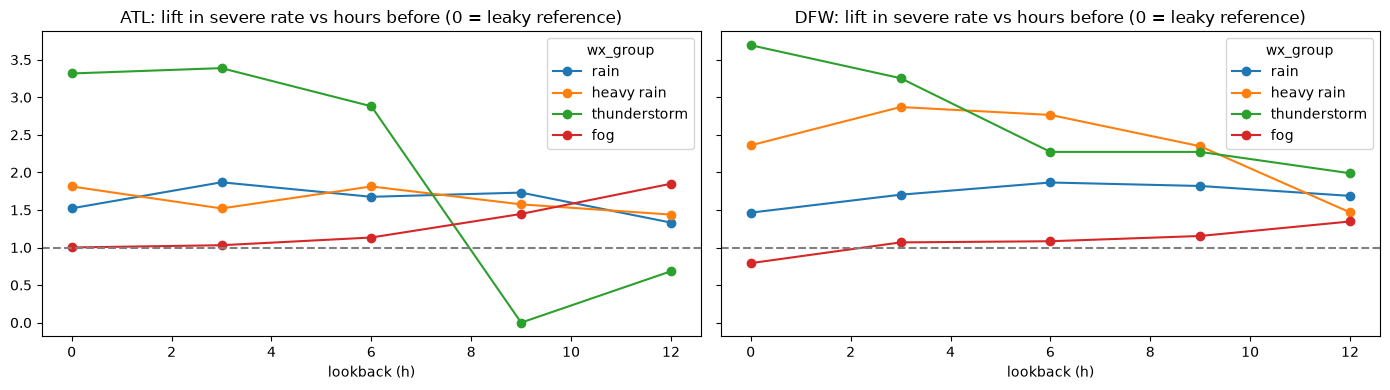

In [44]:
by_lb = lab.groupby(["airport", "lookback", "wx_group"])["severe"].agg(["size", "mean"])
overall_lb = lab.groupby(["airport", "lookback"])["severe"].mean()
by_lb["lift"] = by_lb["mean"] / overall_lb.reindex(by_lb.index.droplevel("wx_group")).to_numpy()
lift = by_lb["lift"].unstack("wx_group").reindex(columns=WX_GROUP_ORDER)
counts = by_lb["size"].unstack("wx_group").reindex(columns=WX_GROUP_ORDER).fillna(0).astype(int)
print("lift by lookback (both directions)")
display(lift.round(2))
print("targets per cell")
display(counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, a in zip(axes, HUBS):
    lift.loc[a][["rain", "heavy rain", "thunderstorm", "fog"]].plot(ax=ax, marker="o")
    ax.axhline(1, color="grey", linestyle="--")
    ax.set_title(f"{a}: lift in severe rate vs hours before (0 = leaky reference)")
    ax.set_xlabel("lookback (h)")
plt.tight_layout()
plt.show()

### E4. Is it weather, or just time of day and season?

Rain and delays both peak at certain hours and months. **Excess** = severe (0/1) minus the typical rate for the same airport, direction, scheduled hour and month.
Positive excess under bad weather means weather adds information beyond time of day and season.
(The baseline uses the same data; fine for exploration, not for model evaluation.)

In [45]:
excess = lab.groupby(["airport", "lookback", "wx_group"])["excess"].mean().unstack("wx_group").reindex(columns=WX_GROUP_ORDER)
print("mean excess severe rate, percentage points")
(excess * 100).round(1)

mean excess severe rate, percentage points


wx_group          clear  cloudy  fog  rain  heavy rain  snow/ice  thunderstorm
airport lookback                                                              
ATL     0          -1.8     0.5  2.5   3.7         7.1      52.9          14.6
        3          -2.0     0.2  2.9   6.4         4.7      65.4          10.0
        6          -1.7     0.2  2.6   5.3         7.9       NaN          10.1
        9          -1.8     0.4  3.0   5.8         6.5      87.5          -8.4
        12         -1.8     0.9  4.8   3.0         5.4      39.3          -2.0
DFW     0          -2.0     0.6  0.2   7.1        13.4      14.9          27.6
        3          -2.1    -0.1  3.7   9.3        19.6      15.2          24.1
        6          -1.8    -0.5  2.4  10.2        20.6      11.0          19.1
        9          -1.9     0.1  1.7   9.4        17.5       0.9          17.1
        12         -1.9     0.8  2.3   7.7         7.6      13.2          13.6

### E5. Strength of each numeric signal by lookback

Spearman rank correlation between each weather variable and delay minutes, per airport and direction.

In [46]:
SIGNALS = ["temp_c", "dewpoint_c", "rel_humidity_pct", "precip_mm", "wind_speed_kmh", "pressure_hpa",
           "headwind_kmh", "crosswind_kmh", "tailwind_kmh"]
lab["severity"] = lab["wx_group"].map({"clear": 0, "cloudy": 0, "fog": 1, "rain": 2, "heavy rain": 3, "snow/ice": 3, "thunderstorm": 4})
corr = (lab.groupby(["group", "lookback"])
        .apply(lambda g: g[SIGNALS + ["severity"]].corrwith(g["delay"], method="spearman")))
corr.round(3)

temp_c  dewpoint_c  rel_humidity_pct  precip_mm  \
group         lookback                                                    
ATL arrival   0          0.052       0.117             0.120      0.126   
              3          0.100       0.121             0.053      0.129   
              6          0.123       0.129             0.028      0.110   
              9          0.109       0.131             0.062      0.080   
              12         0.070       0.129             0.131      0.090   
ATL departure 0          0.075       0.113             0.064      0.114   
              3          0.110       0.119             0.019      0.113   
              6          0.114       0.126             0.021      0.097   
              9          0.097       0.130             0.070      0.074   
              12         0.066       0.129             0.131      0.052   
DFW arrival   0          0.005       0.054             0.067      0.080   
              3          0.063       0.062            -0.007      0.100   
              6          0.085       0.075            -0.021      0.075   
              9          0.063       0.089             0.043      0.081   
              12         0.022       0.096             0.134      0.056   
DFW departure 0          0.085       0.088             0.010      0.085   
              3          0.121       0.099            -0.037      0.114   
              6          0.110       0.112            -0.007      0.084   
              9          0.077       0.122             0.076      0.071   
              12         0.038       0.132             0.161      0.059   

                        wind_speed_kmh  pressure_hpa  headwind_kmh  \
group         lookback                                               
ATL arrival   0                  0.020        -0.111         0.007   
              3                  0.049        -0.113        -0.009   
              6                  0.064        -0.093        -0.009   
              9                  0.057        -0.061         0.000   
              12                 0.027        -0.057         0.027   
ATL departure 0                  0.030        -0.119        -0.057   
              3                  0.083        -0.114        -0.075   
              6                  0.068        -0.097        -0.051   
              9                  0.052        -0.087        -0.038   
              12                 0.020        -0.084        -0.012   
DFW arrival   0                  0.061        -0.103        -0.069   
              3                  0.094        -0.114        -0.052   
              6                  0.102        -0.093        -0.028   
              9                  0.087        -0.079        -0.024   
              12                 0.059        -0.092        -0.011   
DFW departure 0                  0.050        -0.096        -0.031   
              3                  0.075        -0.082        -0.012   
              6                  0.074        -0.055        -0.011   
              9                  0.054        -0.052        -0.006   
              12                 0.027        -0.058         0.005   

                        crosswind_kmh  tailwind_kmh  severity  
group         lookback                                         
ATL arrival   0                 0.016        -0.000     0.144  
              3                 0.020         0.019     0.139  
              6                 0.037         0.018     0.127  
              9                 0.035         0.014     0.136  
              12                0.002        -0.022     0.121  
ATL departure 0                 0.031         0.054     0.117  
              3                 0.066         0.081     0.134  
              6                 0.062         0.055     0.111  
              9                 0.028         0.050     0.110  
              12                0.023         0.017     0.090  
DFW arrival   0                 0.086         0.094     0.095  


### E6. Window features (3-12 h window)

Summaries over every hour in the allowed window (D4) vs severe rate, and their correlation with delay minutes.

In [47]:
wf = window_feats[window_feats["severe"].notna()].copy()
wf["severe"] = wf["severe"].astype(bool)
for col in ["win_any_rain", "win_any_severe_wx", "win_any_thunder"]:
    print(col)
    display(rate_by(wf, col).round(3))
wf["pressure_change_band"] = pd.cut(wf["win_pressure_change"], [-np.inf, -3, -1, 1, 3, np.inf],
                                    labels=["falling > 3", "falling 1-3", "steady", "rising 1-3", "rising > 3"])
print("pressure change across the window (hPa)")
display(rate_by(wf, "pressure_change_band").round(3))

WIN = [c for c in wf.columns if c.startswith("win_")]
print("Spearman correlation with delay minutes")
wf.groupby("group").apply(lambda g: g[WIN].corrwith(g["delay"], method="spearman")).round(3)

win_any_rain


,ATL arrival n,ATL arrival rate,ATL departure n,ATL departure rate,DFW arrival n,DFW arrival rate,DFW departure n,DFW departure rate
win_any_rain,,,,,,,,
0.0,4145,0.073,6546,0.078,3360,0.105,6505,0.115
1.0,1216,0.139,1796,0.151,563,0.188,1106,0.220


win_any_severe_wx


,ATL arrival n,ATL arrival rate,ATL departure n,ATL departure rate,DFW arrival n,DFW arrival rate,DFW departure n,DFW departure rate
win_any_severe_wx,,,,,,,,
0.0,4966,0.082,7701,0.087,3648,0.106,7087,0.119
1.0,395,0.162,641,0.175,275,0.262,524,0.277


win_any_thunder


,ATL arrival n,ATL arrival rate,ATL departure n,ATL departure rate,DFW arrival n,DFW arrival rate,DFW departure n,DFW departure rate
win_any_thunder,,,,,,,,
0.0,5307,0.086,8276,0.092,3872,0.114,7508,0.128
1.0,54,0.315,66,0.273,51,0.353,103,0.262


pressure change across the window (hPa)


,ATL arrival n,ATL arrival rate,ATL departure n,ATL departure rate,DFW arrival n,DFW arrival rate,DFW departure n,DFW departure rate
pressure_change_band,,,,,,,,
falling > 3,634,0.129,1027,0.130,646,0.147,1254,0.144
falling 1-3,1233,0.118,1739,0.123,742,0.120,1376,0.162
steady,1833,0.082,2848,0.086,1065,0.119,2121,0.122
rising 1-3,1264,0.055,2091,0.067,1015,0.096,1953,0.103
rising > 3,397,0.060,637,0.075,455,0.112,907,0.141


Spearman correlation with delay minutes


,win_max_precip,win_any_rain,win_any_severe_wx,win_any_thunder,win_max_wind,win_max_crosswind,win_max_tailwind,win_pressure_change
group,,,,,,,,
ATL arrival,0.150,0.142,0.131,0.069,0.082,0.063,0.040,-0.120
ATL departure,0.130,0.124,0.106,0.051,0.086,0.075,0.079,-0.063
DFW arrival,0.129,0.125,0.118,0.082,0.120,0.136,0.097,-0.049
DFW departure,0.129,0.125,0.116,0.057,0.085,0.102,0.050,-0.052


### E7. Weather cancellations

Share of targets cancelled for weather (code B), by heavy weather or thunderstorm anywhere in the 3-12 h window. Includes cancelled flights.

In [48]:
wc = window_feats.assign(weather_cancel=window_feats["CANCELLATION_CODE"].eq("B"))
pd.concat({
    "heavy weather in window: no / yes": wc.groupby(["group", "win_any_severe_wx"])["weather_cancel"].mean().unstack().set_axis(["no", "yes"], axis=1),
    "thunderstorm in window: no / yes": wc.groupby(["group", "win_any_thunder"])["weather_cancel"].mean().unstack().set_axis(["no", "yes"], axis=1),
}, axis=1).round(3)

heavy weather in window: no / yes         \
                                             no    yes   
group                                                    
ATL arrival                               0.004  0.015   
ATL departure                             0.003  0.021   
DFW arrival                               0.011  0.125   
DFW departure                             0.010  0.074   

              thunderstorm in window: no / yes         
                                            no    yes  
group                                                  
ATL arrival                              0.005  0.000  
ATL departure                            0.004  0.029  
DFW arrival                              0.018  0.117  
DFW departure                            0.014  0.055

## F. Runway Wind

The brief warns against using raw wind speed instead of runway components. With the brief's fixed headings (ATL 80°, DFW 180°):
how often are typical wind limits exceeded, and does direction add information beyond speed?

**Reference limits (assumption, not from the data):** about **10 kt (18.5 km/h) tailwind** and **20 kt (37 km/h) crosswind**,
typical airline operating limits for dry runways; real limits vary by aircraft type and runway condition.

In [49]:
KMH_PER_KT = 1.852
TAILWIND_LIMIT = 10 * KMH_PER_KT
CROSSWIND_LIMIT = 20 * KMH_PER_KT
wx["over_tailwind_limit"] = wx["tailwind_kmh"] > TAILWIND_LIMIT
wx["over_crosswind_limit"] = wx["crosswind_kmh"] > CROSSWIND_LIMIT
wx["over_any_limit"] = wx["over_tailwind_limit"] | wx["over_crosswind_limit"]

### F1. How often are the limits exceeded?

,over_tailwind_limit (% of hours),over_crosswind_limit (% of hours),over_any_limit (% of hours)
airport,,,
ATL,3.83,0.04,3.87
DFW,7.70,0.12,7.78


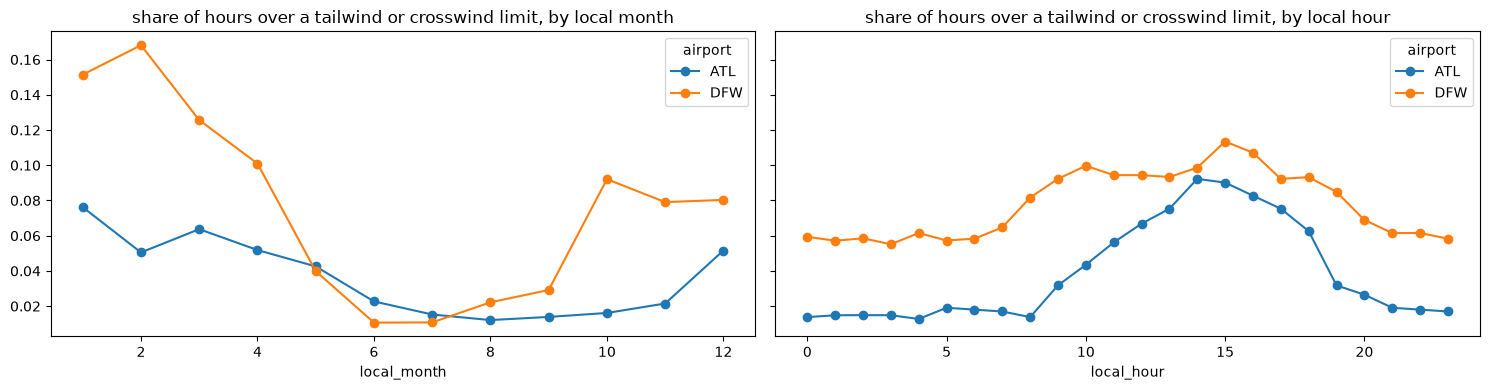

In [50]:
display((wx.groupby("airport")[["over_tailwind_limit", "over_crosswind_limit", "over_any_limit"]].mean() * 100).round(2)
        .rename(columns=lambda c: c + " (% of hours)"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, ["local_month", "local_hour"]):
    wx.groupby([col, "airport"])["over_any_limit"].mean().unstack().plot(ax=ax, marker="o")
    ax.set_title(f"share of hours over a tailwind or crosswind limit, by {col.replace('_', ' ')}")
plt.tight_layout()
plt.show()

### F2. Severe rate when a limit was exceeded 3 h before, or anywhere in the 3-12 h window

In [51]:
l3 = lab[lab["lookback"] == 3].copy()
l3["over_tailwind_limit"] = l3["tailwind_kmh"] > TAILWIND_LIMIT
l3["over_crosswind_limit"] = l3["crosswind_kmh"] > CROSSWIND_LIMIT
display(rate_by(l3, "over_tailwind_limit").round(3))
display(rate_by(l3, "over_crosswind_limit").round(3))

wf["window_over_tailwind"] = wf["win_max_tailwind"] > TAILWIND_LIMIT
wf["window_over_crosswind"] = wf["win_max_crosswind"] > CROSSWIND_LIMIT
display(rate_by(wf, "window_over_tailwind").round(3))
rate_by(wf, "window_over_crosswind").round(3)

,ATL arrival n,ATL arrival rate,ATL departure n,ATL departure rate,DFW arrival n,DFW arrival rate,DFW departure n,DFW departure rate
over_tailwind_limit,,,,,,,,
False,5135,0.087,7994,0.091,3598,0.112,7005,0.127
True,226,0.119,349,0.143,325,0.169,606,0.170


,ATL arrival n,ATL arrival rate,ATL departure n,ATL departure rate,DFW arrival n,DFW arrival rate,DFW departure n,DFW departure rate
over_crosswind_limit,,,,,,,,
False,5361.0,0.088,8340.0,0.094,3920.0,0.117,7606.0,0.13
True,NaN,NaN,3.0,0.000,3.0,0.000,5.0,0.20


,ATL arrival n,ATL arrival rate,ATL departure n,ATL departure rate,DFW arrival n,DFW arrival rate,DFW departure n,DFW departure rate
window_over_tailwind,,,,,,,,
False,4723,0.083,7400,0.088,3286,0.109,6370,0.122
True,638,0.129,943,0.138,637,0.159,1241,0.171


,ATL arrival n,ATL arrival rate,ATL departure n,ATL departure rate,DFW arrival n,DFW arrival rate,DFW departure n,DFW departure rate
window_over_crosswind,,,,,,,,
False,5355,0.088,8321,0.094,3908,0.117,7583,0.129
True,6,0.000,22,0.045,15,0.200,28,0.357


### F3. Does direction add information beyond speed?

Among targets where the wind 3 h before was at least 20 km/h, split by which component dominated:
mostly headwind, mostly crosswind, or mostly tailwind. If the severe rate differs at similar speeds, direction matters.

In [52]:
strong = l3[l3["wind_speed_kmh"] >= 20].copy()
comp = pd.DataFrame({"headwind": strong["headwind_kmh"].clip(lower=0),
                     "crosswind": strong["crosswind_kmh"], "tailwind": strong["tailwind_kmh"]})
strong["dominant"] = comp.idxmax(axis=1)
summary = strong.groupby(["group", "dominant"]).agg(n=("severe", "size"), severe_rate=("severe", "mean"),
                                                    mean_speed=("wind_speed_kmh", "mean"))
display(summary.round(3))

print("Spearman correlation with delay minutes, 3 h before and window max")
pd.DataFrame({
    "speed (3 h)": lab[lab["lookback"] == 3].groupby("group").apply(lambda g: g["wind_speed_kmh"].corr(g["delay"], method="spearman")),
    "crosswind (3 h)": lab[lab["lookback"] == 3].groupby("group").apply(lambda g: g["crosswind_kmh"].corr(g["delay"], method="spearman")),
    "tailwind (3 h)": lab[lab["lookback"] == 3].groupby("group").apply(lambda g: g["tailwind_kmh"].corr(g["delay"], method="spearman")),
    "max speed (window)": wf.groupby("group").apply(lambda g: g["win_max_wind"].corr(g["delay"], method="spearman")),
    "max crosswind (window)": wf.groupby("group").apply(lambda g: g["win_max_crosswind"].corr(g["delay"], method="spearman")),
    "max tailwind (window)": wf.groupby("group").apply(lambda g: g["win_max_tailwind"].corr(g["delay"], method="spearman")),
}).round(3)

n  severe_rate  mean_speed
group         dominant                                
ATL arrival   crosswind   373        0.091      24.417
              headwind    257        0.051      23.891
              tailwind    278        0.126      24.926
ATL departure crosswind   609        0.110      24.524
              headwind    400        0.100      23.814
              tailwind    416        0.139      25.185
DFW arrival   crosswind   163        0.147      25.631
              headwind    879        0.118      25.851
              tailwind    348        0.161      27.175
DFW departure crosswind   331        0.190      25.970
              headwind   1713        0.135      25.839
              tailwind    640        0.170      26.696

Spearman correlation with delay minutes, 3 h before and window max


,speed (3 h),crosswind (3 h),tailwind (3 h),max speed (window),max crosswind (window),max tailwind (window)
group,,,,,,
ATL arrival,0.049,0.020,0.019,0.082,0.063,0.040
ATL departure,0.083,0.066,0.081,0.086,0.075,0.079
DFW arrival,0.094,0.066,0.101,0.120,0.136,0.097
DFW departure,0.075,0.076,0.037,0.085,0.102,0.050


## G. Severe Weather Events

**Working definition (exploration only):** a severe-weather hour is heavy rain, thunderstorm or snow/ice, or precipitation > 5 mm, or wind > 40 km/h.
Consecutive severe hours (gaps up to 2 h) form an event.

### G1. Severe-weather hours and events

severe hours: {'ATL': {'sum': 744, 'mean': 0.033}, 'DFW': {'sum': 890, 'mean': 0.039}}
events: {'ATL': 243, 'DFW': 319}


severe_hours                                     span_hours            \
               count mean  std  min  25%  50%  75%   max      count mean  std   
airport                                                                         
ATL            243.0  3.1  4.2  1.0  1.0  2.0  3.0  47.0      243.0  3.2  4.4   
DFW            319.0  2.8  2.9  1.0  1.0  2.0  3.0  24.0      319.0  2.9  3.1   

                                   
         min  25%  50%  75%   max  
airport                            
ATL      1.0  1.0  2.0  4.0  48.0  
DFW      1.0  1.0  2.0  4.0  24.0

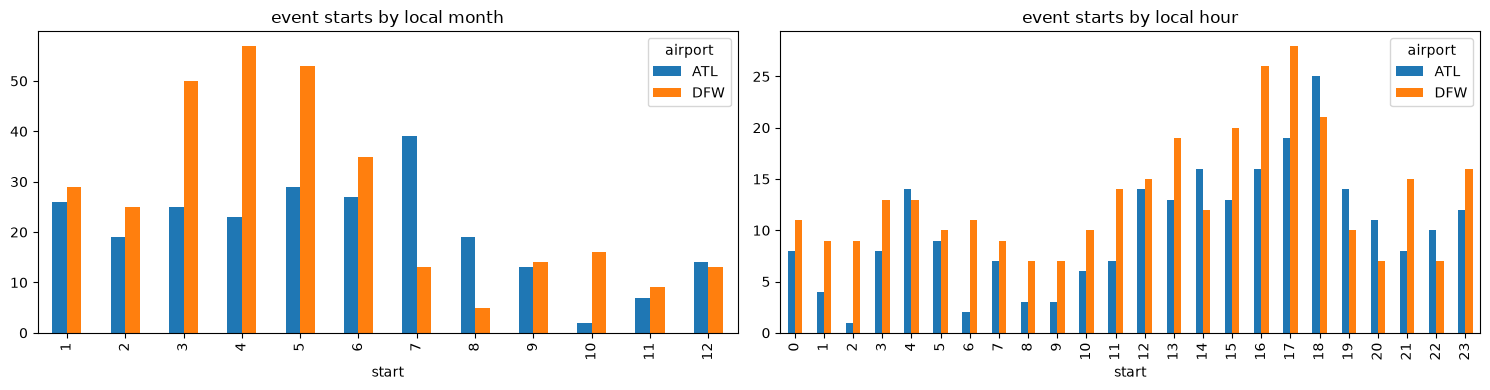

In [53]:
wx["severe_hour"] = wx["wx_group"].isin(["heavy rain", "thunderstorm", "snow/ice"]) | (wx["precip_mm"] > 5) | (wx["wind_speed_kmh"] > 40)

def find_events(times: pd.Series, max_gap_h: int = 2) -> pd.DataFrame:
    times = times.sort_values().reset_index(drop=True)
    new_event = times.diff() > pd.Timedelta(hours=max_gap_h)
    ev = times.groupby(new_event.cumsum()).agg(["min", "max", "size"])
    ev.columns = ["start", "end", "severe_hours"]
    ev["span_hours"] = (ev["end"] - ev["start"]) / pd.Timedelta(hours=1) + 1
    return ev

events = pd.concat({a: find_events(g.loc[g["severe_hour"], "time_utc"]) for a, g in wx.groupby("airport")},
                   names=["airport", "event"])
print("severe hours:", wx.groupby("airport")["severe_hour"].agg(["sum", "mean"]).round(3).to_dict("index"))
print("events:", events.groupby("airport").size().to_dict())
display(events.groupby("airport")[["severe_hours", "span_hours"]].describe().round(1))

starts_local = pd.concat([events.loc[a, "start"].dt.tz_localize("UTC").dt.tz_convert(tz).dt.tz_localize(None).to_frame().assign(airport=a)
                          for a, tz in HUB_TZ.items()])
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
starts_local.groupby([starts_local["start"].dt.month, "airport"]).size().unstack(fill_value=0).plot(kind="bar", ax=axes[0])
axes[0].set_title("event starts by local month")
starts_local.groupby([starts_local["start"].dt.hour, "airport"]).size().unstack(fill_value=0).reindex(range(24), fill_value=0).plot(kind="bar", ax=axes[1])
axes[1].set_title("event starts by local hour")
plt.tight_layout()
plt.show()

### G2. Delays and cancellations around events

For each target within 12 h of an event start (nearest event at its airport): severe rate and weather-cancellation rate
by hours from the event start (2-hour bins). Negative = scheduled before the event began.

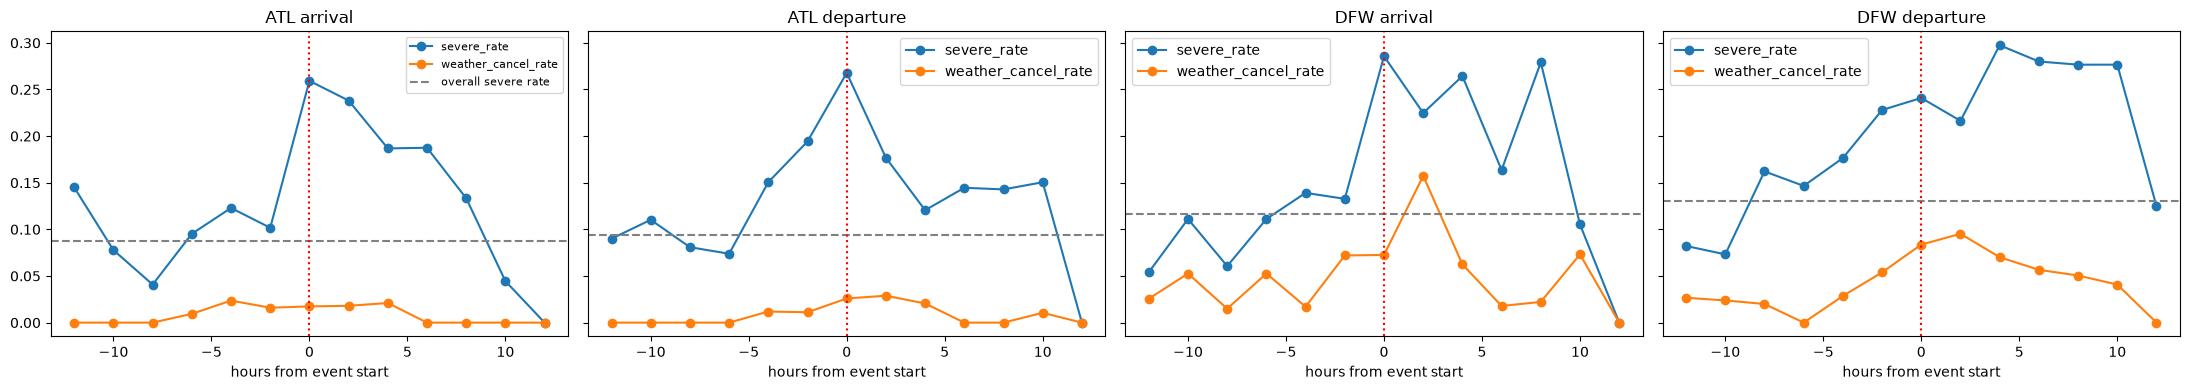

group,ATL arrival,ATL departure,DFW arrival,DFW departure
bin,,,,
-12,0.144928,0.09,0.054054,0.082192
-10,0.077778,0.110236,0.111111,0.073171
-8,0.040816,0.080882,0.060606,0.162162
-6,0.095238,0.073864,0.111111,0.146597
-4,0.122951,0.150602,0.13913,0.176471
-2,0.101695,0.194286,0.132743,0.227979
0,0.259259,0.26776,0.285714,0.240909
2,0.238095,0.176768,0.224719,0.216374
4,0.186813,0.120567,0.264368,0.297468


In [54]:
rows = []
for a in HUBS:
    starts = np.sort(events.loc[a, "start"].to_numpy())
    t = targets[(targets["airport"] == a) & targets["sched_utc"].notna()]
    fv = t["sched_utc"].to_numpy()
    pos = np.clip(np.searchsorted(starts, fv), 1, len(starts) - 1)
    prev, nxt = starts[pos - 1], starts[pos]
    nearest = np.where(np.abs(fv - prev) <= np.abs(nxt - fv), prev, nxt)
    rel = (fv - nearest) / np.timedelta64(1, "h")
    part = t[["group", "role", "severe", "CANCELLATION_CODE"]].copy()
    part["rel_hours"] = rel
    rows.append(part[np.abs(rel) <= 12])

around = pd.concat(rows)
around["bin"] = (np.floor(around["rel_hours"] / 2) * 2).astype(int)
around["weather_cancel"] = around["CANCELLATION_CODE"].eq("B")
study = around.groupby(["group", "bin"]).agg(targets=("bin", "size"), severe_rate=("severe", "mean"),
                                             weather_cancel_rate=("weather_cancel", "mean"))

fig, axes = plt.subplots(1, 4, figsize=(22, 4), sharey=True)
for ax, g in zip(axes, sorted(targets["group"].unique())):
    s = study.loc[g]
    s[["severe_rate", "weather_cancel_rate"]].plot(ax=ax, marker="o")
    ax.axhline(overall[g], color="grey", linestyle="--", label="overall severe rate")
    ax.axvline(0, color="red", linestyle=":")
    ax.set_title(g)
    ax.set_xlabel("hours from event start")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
study.unstack("group")["severe_rate"].round(3)

### G3. Can an event be seen coming 3-12 h ahead from observations alone?

For every hour t: does a severe-weather hour occur between t+3 and t+12? Simple warning rules using only weather at or before t:
how often each rule fires, how often it is right when it fires (precision), and what share of upcoming severe weather it catches (recall).

In [55]:
rules = []
for a, g in wx.groupby("airport"):
    g = g.set_index("time_utc").sort_index()
    sev = g["severe_hour"].astype(float)
    # any severe hour in (t+3 .. t+12]
    upcoming = sev[::-1].rolling(10, min_periods=1).max()[::-1].shift(-3)
    signals = {
        "rain now": g["rain_any"],
        "severe weather now": g["severe_hour"],
        "pressure fell > 2 hPa in 3 h": (g["pressure_hpa"] - g["pressure_hpa"].shift(3)) < -2,
        "humidity > 90%": g["rel_humidity_pct"] > 90,
        "dew point > 20 °C": g["dewpoint_c"] > 20,
    }
    ok = upcoming.notna()
    y = upcoming[ok].astype(bool)
    for name, sig in signals.items():
        s = sig[ok].fillna(False).astype(bool)
        rules.append({"airport": a, "rule": name, "fires (% of hours)": s.mean() * 100,
                      "precision": y[s].mean(), "recall": s[y].mean(), "base rate": y.mean()})
pd.DataFrame(rules).set_index(["airport", "rule"]).round(3)

fires (% of hours)  precision  recall  \
airport rule                                                                  
ATL     rain now                                   8.273      0.386   0.274   
        severe weather now                         3.279      0.571   0.161   
        pressure fell > 2 hPa in 3 h               6.792      0.245   0.143   
        humidity > 90%                             6.611      0.309   0.175   
        dew point > 20 °C                         15.003      0.213   0.274   
DFW     rain now                                   5.449      0.441   0.167   
        severe weather now                         3.933      0.585   0.160   
        pressure fell > 2 hPa in 3 h               9.214      0.185   0.119   
        humidity > 90%                             6.558      0.290   0.132   
        dew point > 20 °C                         22.537      0.172   0.270   

                                      base rate  
airport rule                                     
ATL     rain now                          0.117  
        severe weather now                0.117  
        pressure fell > 2 hPa in 3 h      0.117  
        humidity > 90%                    0.117  
        dew point > 20 °C                 0.117  
DFW     rain now                          0.144  
        severe weather now                0.144  
        pressure fell > 2 hPa in 3 h      0.144  
        humidity > 90%                    0.144  
        dew point > 20 °C                 0.144

### G4. Worst delay days: was severe weather seen?

The 15 worst days per airport (severe rate, days with 10+ targets in both directions), whether a severe-weather hour was observed that local day,
and the day's split of severe-delay minutes by cause. Days with no severe weather are **candidate failure cases** for a weather-based model.

In [56]:
lt = labelled.copy()
lt["local_date"] = lt["sched_date"].dt.date
daily_t = lt.groupby(["airport", "local_date"]).agg(targets=("severe", "size"), severe=("severe", "sum"), severe_rate=("severe", "mean"))

wx_days = wx[wx["severe_hour"]].assign(local_date=wx["time_local"].dt.date).groupby("airport")["local_date"].apply(set)
day_causes = lt[lt["severe"]].groupby(["airport", "local_date"])[CAUSES].sum()
day_causes = day_causes.div(day_causes.sum(axis=1), axis=0)

worst = []
for a in HUBS:
    d = daily_t.loc[a]
    top = d[d["targets"] >= 10].sort_values(["severe_rate", "targets"], ascending=False).head(15).copy()
    top["severe_wx_seen"] = [day in wx_days.get(a, set()) for day in top.index]
    top = top.join(day_causes.loc[a][["WEATHER_DELAY", "NAS_DELAY", "LATE_AIRCRAFT_DELAY", "CARRIER_DELAY"]].round(2))
    top.insert(0, "airport", a)
    worst.append(top)
worst = pd.concat(worst)
print("worst days with severe weather observed:", worst.groupby("airport")["severe_wx_seen"].sum().to_dict(), "of 15")
worst.round(3)

worst days with severe weather observed: {'ATL': 9, 'DFW': 11} of 15


,airport,targets,severe,severe_rate,severe_wx_seen,WEATHER_DELAY,NAS_DELAY,LATE_AIRCRAFT_DELAY,CARRIER_DELAY
local_date,,,,,,,,,
2024-07-21,ATL,14,11,0.786,False,0.00,0.11,0.45,0.44
2024-05-27,ATL,18,13,0.722,True,0.10,0.21,0.56,0.12
2025-06-28,ATL,12,8,0.667,False,0.09,0.09,0.15,0.67
2024-12-28,ATL,11,7,0.636,False,0.00,0.26,0.55,0.19
2025-02-16,ATL,11,7,0.636,True,0.00,0.10,0.39,0.51
2024-07-20,ATL,12,7,0.583,True,0.00,0.21,0.35,0.44
2023-03-26,ATL,14,8,0.571,True,0.17,0.08,0.34,0.40
2025-04-06,ATL,14,8,0.571,True,0.29,0.16,0.50,0.06
2023-03-25,ATL,11,6,0.545,True,0.00,0.17,0.47,0.36


## H. Leakage and Modelling Prep

What a model may use at prediction time (3-12 h before the scheduled time), what is outcome-only, class balance, data over time,
and what the "any airport" requirement needs beyond ATL/DFW.

### H1. Column roles in the flights file

In [57]:
KNOWN_AT_SCHEDULE = {
    "YEAR", "QUARTER", "MONTH", "DAY_OF_MONTH", "DAY_OF_WEEK", "FL_DATE",
    "OP_UNIQUE_CARRIER", "OP_CARRIER_AIRLINE_ID", "OP_CARRIER", "OP_CARRIER_FL_NUM",
    "CRS_DEP_TIME", "CRS_ARR_TIME", "DEP_TIME_BLK", "ARR_TIME_BLK", "CRS_ELAPSED_TIME",
    "DISTANCE", "DISTANCE_GROUP", "FLIGHTS",
}

def column_role(col: str) -> str:
    group = flight_column_group(col)
    if col in KNOWN_AT_SCHEDULE or group in {"origin", "destination"}:
        return "input: known from the schedule"
    if col == "TAIL_NUM":
        return "input with care: aircraft can be swapped on the day"
    if group.startswith("weather"):
        return "do not use: mistimed weather (D2); use the hourly file instead"
    if group in {"diversion details", "gate return"}:
        return "outcome, mostly empty"
    return "outcome: label only, never an input"

roles = pd.DataFrame({"group": [flight_column_group(c) for c in flights.columns],
                      "role": [column_role(c) for c in flights.columns]}, index=flights.columns)
display(roles["role"].value_counts().to_frame("columns"))
roles[roles["role"] != "outcome, mostly empty"]

,columns
role,
"outcome, mostly empty",49
input: known from the schedule,36
"outcome: label only, never an input",23
do not use: mistimed weather (D2); use the hourly file instead,14
input with care: aircraft can be swapped on the day,1


,group,role
YEAR,date,input: known from the schedule
QUARTER,date,input: known from the schedule
MONTH,date,input: known from the schedule
DAY_OF_MONTH,date,input: known from the schedule
DAY_OF_WEEK,date,input: known from the schedule
FL_DATE,date,input: known from the schedule
OP_UNIQUE_CARRIER,carrier,input: known from the schedule
OP_CARRIER_AIRLINE_ID,carrier,input: known from the schedule
OP_CARRIER,carrier,input: known from the schedule
TAIL_NUM,carrier,input with care: aircraft can be swapped on th...


### H2. An arrival's own departure delay

For an arrival into ATL/DFW, its departure delay at the origin is known once it departs. That is only usable if the departure
happens before the prediction time (3-12 h before the scheduled arrival), i.e. for long flights.

In [58]:
elapsed = flights.loc[flights["DEST"].isin(HUBS), "CRS_ELAPSED_TIME"].to_numpy()
for horizon in [3, 6, 9, 12]:
    print(f"arrivals whose scheduled flight time is >= {horizon} h (departure known at a {horizon} h horizon): {(elapsed >= horizon * 60).mean():.1%}")

arrivals whose scheduled flight time is >= 3 h (departure known at a 3 h horizon): 28.3%
arrivals whose scheduled flight time is >= 6 h (departure known at a 6 h horizon): 0.1%
arrivals whose scheduled flight time is >= 9 h (departure known at a 9 h horizon): 0.0%
arrivals whose scheduled flight time is >= 12 h (departure known at a 12 h horizon): 0.0%


### H3. Is the aircraft's previous flight in the data?

Late-arriving aircraft are the largest delay cause (B5). For a departure from ATL/DFW: is the same aircraft's earlier inbound flight
into that airport on the same day in the file? With a ~1% sample, probably rarely.

In [59]:
inbound = flights[flights["DEST"].isin(HUBS)][["TAIL_NUM", "FL_DATE", "DEST", "CRS_ARR_TIME"]].dropna()
outbound = flights[flights["ORIGIN"].isin(HUBS)][["TAIL_NUM", "FL_DATE", "ORIGIN", "CRS_DEP_TIME"]].dropna()
pairs = outbound.merge(inbound, left_on=["TAIL_NUM", "FL_DATE", "ORIGIN"], right_on=["TAIL_NUM", "FL_DATE", "DEST"])
pairs = pairs[pairs["CRS_ARR_TIME"] < pairs["CRS_DEP_TIME"]]
FLIGHT_ID = ["TAIL_NUM", "FL_DATE", "CRS_DEP_TIME"]
has_inbound = outbound.set_index(FLIGHT_ID).index.isin(pairs.set_index(FLIGHT_ID).index)
print(f"departures whose same-day inbound flight is in the file: {has_inbound.mean():.1%} ({has_inbound.sum()} of {len(outbound):,})")

departures whose same-day inbound flight is in the file: 0.7% (105 of 16,137)


### H4. Class balance and data over time

Positives per airport and direction, and per half-year, to inform a time-based train/test split (train on earlier, test on later).

In [60]:
labelled["half"] = labelled["sched_date"].dt.year.astype(str) + "-H" + np.where(labelled["sched_date"].dt.month <= 6, "1", "2")
balance = labelled.groupby(["half", "group"]).agg(targets=("severe", "size"), positives=("severe", "sum"), rate=("severe", "mean"))
display(balance.unstack("group").round(3))
print("note: 2025-H2 contains July 2025 only")

targets                                           positives  \
group   ATL arrival ATL departure DFW arrival DFW departure ATL arrival   
half                                                                      
2023-H1        1013          1598         670          1315          87   
2023-H2        1081          1671         795          1482         103   
2024-H1         970          1629         734          1465          75   
2024-H2        1032          1681         811          1572          79   
2025-H1        1068          1487         767          1500          99   
2025-H2         197           277         146           277          29   

                                                       rate                \
group   ATL departure DFW arrival DFW departure ATL arrival ATL departure   
half                                                                        
2023-H1           140          78           172       0.086         0.088   
2023-H2           131          52           146       0.095         0.078   
2024-H1           131         110           234       0.077         0.080   
2024-H2           149          84           174       0.077         0.089   
2025-H1           180         105           207       0.093         0.121   
2025-H2            49          30            58       0.147         0.177   

                                   
group   DFW arrival DFW departure  
half                               
2023-H1       0.116         0.131  
2023-H2       0.065         0.099  
2024-H1       0.150         0.160  
2024-H2       0.104         0.111  
2025-H1       0.137         0.138  
2025-H2       0.205         0.209

note: 2025-H2 contains July 2025 only


### H5. What "any airport" needs

The pipeline must accept any IATA/ICAO code, but the hourly weather file covers only ATL and DFW. Inputs a new airport needs, and where they could come from:

| Input | ATL/DFW today | Another airport |
|---|---|---|
| Flights and delays | flights file | flights file (57 airports have 1,000+ rows, A1), or full BTS data by script |
| Hourly weather with wind direction | provided file | public source fetched by script, e.g. Meteostat or NOAA ISD (same source as the provided file) |
| Time zone | set by hand (D1) | public airport database |
| Runway heading | brief's assumption (80°, 180°) | public runway data, or a stated assumption |

Airports with the most targets beyond ATL/DFW (departures + arrivals):

In [61]:
airports.drop(HUBS).head(10)

,as_origin,as_dest,total
DEN,7687,5408,13095
ORD,7103,4634,11737
LAX,4832,4443,9275
PHX,4798,4015,8813
LAS,4834,3964,8798
CLT,5147,3270,8417
MCO,4057,3581,7638
LGA,3976,3017,6993
SEA,4181,2715,6896
BOS,3591,3002,6593


## I. Data Quality

### I1. Flights file: duplicates, time formats, inconsistent values

In [62]:
FLIGHT_KEY = ["FL_DATE", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM", "ORIGIN", "DEST", "CRS_DEP_TIME"]
TIME_COLS = ["CRS_DEP_TIME", "DEP_TIME", "WHEELS_OFF", "WHEELS_ON", "CRS_ARR_TIME", "ARR_TIME"]

dep_clock = (flights["DEP_TIME"] // 100) * 60 + flights["DEP_TIME"] % 100
crs_clock = (flights["CRS_DEP_TIME"] // 100) * 60 + flights["CRS_DEP_TIME"] % 100
clock_diff = ((dep_clock - crs_clock + 720) % 1440) - 720
checks = {
    "exact duplicate rows": flights.duplicated(),
    "duplicate flight keys": flights.duplicated(FLIGHT_KEY),
    "time written as 2400 (midnight)": (flights[TIME_COLS] == 2400).any(axis=1),
    "minutes above 59 in a time": ((flights[TIME_COLS] % 100) > 59).any(axis=1),
    "DEP_DELAY != actual - scheduled": (clock_diff - flights["DEP_DELAY"]).abs().gt(1) & flights["DEP_DELAY"].abs().lt(720),
    "elapsed != taxi out + air + taxi in": (flights["ACTUAL_ELAPSED_TIME"] - (flights["TAXI_OUT"] + flights["AIR_TIME"] + flights["TAXI_IN"])).abs() > 1,
    "negative taxi time": (flights["TAXI_OUT"] < 0) | (flights["TAXI_IN"] < 0),
    "cancelled but has a departure time": (flights["CANCELLED"] == 1) & flights["DEP_TIME"].notna(),
    "delay > 24 h": (flights["DEP_DELAY"] > 1440) | (flights["ARR_DELAY"] > 1440),
}
pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="rows").to_frame()

,rows
exact duplicate rows,0
duplicate flight keys,0
time written as 2400 (midnight),222
minutes above 59 in a time,0
DEP_DELAY != actual - scheduled,0
elapsed != taxi out + air + taxi in,0
negative taxi time,0
cancelled but has a departure time,77
delay > 24 h,10


### I2. Flights file: weather columns

The update says to ignore `wpgt_*` and `snow_*`; D2 showed all attached weather is mistimed. For completeness:
placeholder shares, and rows filled with the column average (temperature and pressure exactly equal to the mean).

In [63]:
w_cols = [c for c in flights.columns if c.split("_")[0] in WEATHER_PREFIXES]
print("share of zeros:", {c: round((flights[c] == 0).mean(), 3) for c in ["wpgt_ORIGIN", "wpgt_DEST", "snow_ORIGIN", "snow_DEST"]})
for side in ["ORIGIN", "DEST"]:
    filled = np.isclose(flights[f"temp_{side}"], flights[f"temp_{side}"].mean()) & np.isclose(flights[f"pres_{side}"], flights[f"pres_{side}"].mean())
    airport_col = "ORIGIN" if side == "ORIGIN" else "DEST"
    print(f"{side}: {filled.sum():,} average-filled rows; at ATL/DFW: {filled[flights[airport_col].isin(HUBS)].sum()}; "
          f"top airports: {flights.loc[filled, airport_col].value_counts().head(5).to_dict()}")

share of zeros: {'wpgt_ORIGIN': np.float64(0.978), 'wpgt_DEST': np.float64(0.975), 'snow_ORIGIN': np.float64(1.0), 'snow_DEST': np.float64(1.0)}
ORIGIN: 772 average-filled rows; at ATL/DFW: 0; top airports: {'SJU': 746, 'HOU': 16, 'ONT': 6, 'RDM': 2, 'MYR': 1}
DEST: 1,195 average-filled rows; at ATL/DFW: 0; top airports: {'SJU': 862, 'STT': 130, 'YUM': 43, 'STX': 32, 'LAW': 27}


### I3. Hourly weather file: quirks and extremes

In [64]:
quirks = {
    "wind_gust_kmh empty": wx["wind_gust_kmh"].isna().sum(),
    "precip_mm missing": wx["precip_mm"].isna().sum(),
    "condition_code missing": wx["condition_code"].isna().sum(),
    "speed > 0 but direction 0": ((wx["wind_dir_deg"] == 0) & (wx["wind_speed_kmh"] > 0)).sum(),
    "direction written as 360": (wx["wind_dir_deg"] == 360).sum(),
}
display(pd.Series(quirks, name="hours").to_frame())
print("most extreme hours:")
pd.concat([
    wx.nlargest(3, "precip_mm"), wx.nlargest(3, "wind_speed_kmh"), wx.nsmallest(2, "pressure_hpa"),
])[["airport", "time_local", "precip_mm", "wind_speed_kmh", "pressure_hpa", "condition_code", "wx_group"]]

,hours
wind_gust_kmh empty,45264
precip_mm missing,53
condition_code missing,12
speed > 0 but direction 0,57
direction written as 360,740


most extreme hours:


,airport,time_local,precip_mm,wind_speed_kmh,pressure_hpa,condition_code,wx_group
10996,ATL,2024-04-03 00:00:00,62.5,9.4,1001.7,9.0,heavy rain
13299,ATL,2024-07-07 23:00:00,44.5,16.6,1016.8,3.0,cloudy
40875,DFW,2025-01-29 21:00:00,37.6,11.2,1010.9,9.0,heavy rain
19442,ATL,2025-03-20 22:00:00,0.0,86.4,1017.4,2.0,clear
43995,DFW,2025-06-08 22:00:00,0.4,83.0,1009.0,18.0,heavy rain
40286,DFW,2025-01-05 08:00:00,0.2,61.2,1013.0,3.0,cloudy
15249,ATL,2024-09-27 05:00:00,6.9,20.5,985.3,9.0,heavy rain
15248,ATL,2024-09-27 04:00:00,0.5,20.5,987.0,9.0,heavy rain


### I4. Issues and suggested handling

Suggestions only; final choices are made in planning.

| Issue | Where | Suggested handling |
|---|---|---|
| Flights file weather is ~4-6 h older than the flight (local clock hour looked up as UTC) | D2 | Do not use it; join the hourly file on true UTC time |
| `wpgt_*`, `snow_*` placeholders; some average-filled weather rows (not at ATL/DFW) | I2 | Ignore (covered by the rule above) |
| `wind_gust_kmh` empty in the hourly file | C1, I3 | Drop |
| Wind speed > 0 with direction 0 (57 h) | C4, I3 | Treat direction as unknown: components unreliable for those hours |
| Missing precipitation / condition code (a few hours) | C1 | Leave missing, or fill from neighbouring hours |
| Implausible single readings (ATL 86 km/h wind marked clear; 44.5 mm/h rain marked cloudy) | I3 | Flag or cap; real extremes such as Hurricane Helene (ATL, 27 Sep 2024, 985 hPa) look correct |
| Daylight saving: repeated / skipped local hours | C1, D1 | Join on UTC |
| Cancelled / diverted flights have no delay (1.5% of targets) | B1, B3 | Decide in planning: drop, count as severe, or separate outcome |
| Arrivals' delays are mostly set at the origin, which has no hourly weather | B7 | Origin weather from a public source, or accept as a stated limit |
| Late-aircraft delays dominate but inbound flights are almost never in the sample | B5, H3 | Stated limit; full BTS data would fix it |
| Thunderstorms are rare and barely visible 6-12 h ahead in observations | C3, C6, G3 | Stated limit; public forecast data could help |
| Fixed runway headings turn ~31-57% of hours into tailwind hours | C4, F | State the assumption; real airports switch runway direction |

## Summary

**Data**
- Flights: 148,273 rows (Jan 2023 - Jul 2025), a ~1% sample. ATL/DFW give **25,612 prediction targets** (16,151 departures, 9,461 arrivals), ~9 departures and ~5 arrivals per hub per day (A).
- Hourly weather: complete for ATL/DFW (no missing hours), wind components match the stated formulas; gust is empty (C).
- The flights file's own weather is ~4-6 h older than the flight (local clock hour looked up as UTC), so we join the hourly file on true UTC time instead (D2).

**Target**
- 10.7% of targets are severe (ATL 8.8-9.3%, DFW 11.7-13.0%); 1.5% have no delay (cancelled / diverted), mostly weather-cancelled at DFW (B1, B3).
- Severe rate climbs through the day and peaks in July; ATL ranks 4th by raw delay minutes but 16th by rate among the top 20 origins (B4, B6).
- 86% of severe arrivals were already severely late leaving their origin (B7).

**Weather signal (only weather >= 3 h before the scheduled time)**
- Rain 3 h before roughly doubles the severe rate; heavy rain at DFW triples it; thunderstorms push it to 30-40% (small counts) (E1).
- Weather adds information beyond time of day and season: rain +3-10 pts, DFW heavy rain +8-21 pts, thunderstorms +10-28 pts (E4).
- The signal fades over 3-12 h; window summaries (any rain, pressure trend) are slightly stronger than single hours; each variable alone is weak per flight (E3, E5, E6).
- Runway direction matters: at similar wind speeds, tailwind-dominant hours have higher severe rates than headwind-dominant ones (F3).
- Around severe-weather events the severe rate rises from ~10% to 24-29% and stays high for hours (G2).

**Limits to state**
- Observations alone catch only ~16-27% of severe weather 3-12 h ahead, and thunderstorms show almost no warning beyond 3-6 h (C6, G3).
- Late-aircraft delays dominate, but the aircraft's previous flight is almost never in the sample (B5, H3).
- Arrivals' delays are mostly set at origins that have no hourly weather (B7).
- Several of the worst delay days had no severe weather (e.g. ATL 20-23 Jul 2024, both hubs 11 Jan 2023): candidate failure cases (G4).
- Fixed runway headings are the brief's assumption; real airports switch direction (F).

**Open decisions for planning**
- Cancelled / diverted flights in the label; AAR bonus (needs full BTS data); origin weather and forecast data (public, by script);
  time-based train/test split (H4); time zones and runway headings for other airports (H5).